# Holter ECG 전처리 3단계: 잡음 구간 검출 (SQI)

- **앞 단계**: 1단계 `holter_preprocessing.ipynb` (기록 단위 QC), 2단계 `holter_preprocessing_2_filter.ipynb` (필터). 결과 파일 `results/preprocess/record_qc.csv`, `results/preprocess/window_qc/*.npz`만 읽어서 씀
- **대상**: 1단계 통과 708명
- **이 단계가 하는 일 (쉽게)**: 1단계는 "신호가 아예 없는" 10초를 버렸다. 3단계는 **신호는 있는데 심전도가 아닌** 10초를 찾아 "사용 불가"로 표시한다
  - 예: 박동 없이 1초에 33번 규칙적으로 떠는 기계 잡음, 50 Hz 전기 잡음, 몸을 크게 움직여 생긴 큰 흔들림
  - 33 Hz 잡음은 심전도 주파수 범위(0.5–40 Hz) 안이라 **필터로 안 지워진다** (2단계 2-1·2-2) → 구간째 표시해야 함
- **SQI** (Signal Quality Index, 신호 품질 지수): "이 구간이 쓸 만한 심전도인가"를 숫자로 나타낸 값
- **원칙**: 버리는 구간은 지우지 않고 표시만 한다 (2026-10-25 결정). **새 기준은 논문부터 찾고 정한다**
- 근거·상태 표기는 1단계 노트북 맨 위와 같음 (📄 저널 · 🔧 데이터 규칙 · ✋ 자체 기준 / ✅ 확정 · 🔄 확인 중 · ⏸ 보류 · ⬜ 미정)

## 3단계 기준 (최종)

> 2026-10-25 확정. 방법은 논문(3-2), 판정값은 우리 시험 창으로 고르고(3-3 ①~⑦) 새 환자 창으로 한 번만 확인(3-3 ⑧⑨). 708명 전체 적용(3-4) 결과 **창을 빼지 않고 표시만** 하기로 함

| 항목 | 기준 | 근거 | 논문에 적힌 이유 / 근거 내용 | 상태 |
|---|---|---|---|---|
| 두 검출기 일치 (bSQI): 방법 | 유도마다 10초 창, 두 검출기 박동이 150 ms 안이면 같은 박동. 점수 = 같이 찾은 박동 ÷ 둘 중 하나라도 찾은 박동 | 📄 Li 2008 [전문] | 10초: "심박수를 계산하는 창과 맞추려고" / 150 ms: "ANSI/AAMI EC57 권고에 따라" | ✅ |
| 검출기 | neurokit2 `neurokit` + `elgendi2010` | 📄 Kristof 2024 · Porr 2024 [전문] + ✋ | neurokit: 18개 중 "가장 좋은 편" / Elgendi: 파형 모양 변화에 안정적. **조합은 자체 판단**. 처음 쓴 `hamilton2002` + `zong2003`은 neurokit2의 zong이 T파까지 세어 탈락 (3-3 ④) | ✅ |
| 검출기별 전처리 | 각 검출기가 설계된 전처리 그대로 (`nk.ecg_clean(method=검출기)`, Elgendi 8–20 Hz) | 각 검출기 설계 | 다른 전처리를 넣으면 Elgendi가 박동을 두 번 셈 (3-3 ⑦) | ✅ |
| 극성 보정 | 환자·유도마다 깨끗한 창 12개로 방향 판단, 아래로 향한 유도는 **검출할 때만** 뒤집음 (학습 데이터는 원래 방향) | ✋ 자체 판단 (도구: `nk.ecg_invert`) | 저널 근거 없음. 뒤집지 않으면 두 검출기가 QRS 시작점 vs T파를 짚어 깨끗한 유도도 실패 (3-3 ⑤⑥) | ✅ |
| 잡음 판정값 | **bSQI < 0.6** 이면 그 유도 실패 | 📄 Zhao 2018 [전문] | 0.9 이상 최적, 0.6–0.9 의심, 0.6 미만 부적격. 경계값의 이유는 원문에 없음. Zhao 식(2N/(Na+Nb))보다 Li 식이 낮게 나와 우리 판정이 조금 더 엄격 | ✅ |
| 심박수 | **30 bpm 미만**이면 그 유도 실패 | 📄 Sensors 2025 · Sci Rep 2025 [전문] | Sensors: 이유 없음 / Sci Rep: 하한을 "수면 중 예상되는 최저 심박수 33 bpm"에 맞춤 (Caples 2007 인용, 원문 미확인) | ✅ |
| 창 판정 | 남은 유도 중 하나라도 실패하면 그 10초 창은 3단계 실패 (`sqi_pass = 0`) | ✋ 자체 판단 | 1·2단계 유도 기준과 같음 (유도가 모두 깨끗해야 사용) | ✅ |
| 처리 방식 | **빼지 않고 표시만** (창 전체 `sqi_pass` + 유도별 `sqi_X/Y/Z`, `pass_X/Y/Z`) | ✋ 자체 판단 | 전체 적용(3-4 ③): 창이 절반 넘게 걸린 환자 SCD 17% vs 생존 6%, 가장 많이 걸린 환자들은 시험에서 깨끗했던 창까지 걸림 (넓은 QRS·페이스메이커에서 검출기 실패) → 학습에서 넣기/빼기 비교로 결정 | ✅ |
| 시험 정답 규칙 | 유도별 2초 칸 5개, 잡음이 QRS 인식을 방해하는 칸이 하나라도 있으면 사용 불가 (엄격). 끊김 창은 제외, 애매는 따로 표시 | 📄 Li 2014 [전문] | 품질 3등급 "잡음이 QRS 인식을 방해", 4등급 "판독 불가". 엄격 규칙이 문헌에서 가장 많음 (공개 논문 293편 검토, 규칙을 밝힌 14편 중 5편) | ✅ |
| 합격선 | 깨끗한 유도 통과 ≥ 90%, 확실한 잡음 잡기 ≥ 70% (결과 보기 전에 고정) | ✋ 자체 판단 | 논문 기준 없음. 개발용 결과(94%, 77%)보다 약간 낮게 | ✅ |

**뺀 기준**

| 기준 | 뺀 이유 | 상태 |
|---|---|---|
| 유도끼리 일치 (iSQI) | 계산은 했지만 판정에는 안 씀. 판정값과 합치는 방법에 근거가 없고, 표시만 하기로 하면서 필요성이 줄어듦 | ⏸ |
| 심박수 상한 (180·240 bpm) | 상한 근거가 약하고(240은 이유 없음), 시험 창에서 문제 사례 없음 | ⏸ |
| 박동 규칙 (박동 간격 3초 초과, 가장 긴 간격 ÷ 가장 짧은 간격 ≥ 2.2) | 원조 Orphanidou 2015 (IEEE)를 받을 수 없음. 대신 인용한 Vorreuther 2025는 건강한 15명 대상이고, 2.2의 이유가 숫자와 맞지 않음 | ⏸ 참고만 |
| 첨도·주파수 비율·기저선 (Zhao 2018의 나머지 지표) | Rahman 2022: 고정 기준값으로는 데이터셋마다 크게 흔들림 | ⏸ |
| neurokit2 `ecg_quality(method="zhao2018")` | 두 검출기 일치가 빠져 있음 (설치된 코드에서 확인) | ⏸ |
| R파 높이 (mV), Neri 표준편차 2배 | 저널 근거 없음 (특허만) / 3단계를 bSQI로 정하면서 쓰지 않음 | ⏸ |

**결과 요약**

| 시험 | 깨끗한 유도 통과 | 잡음 잡기 (확실한 정답) |
|---|---|---|
| 개발용 94창 (3-3 ⑦, 판정값 0.6) | 220/234 (94%) | 17/22 (77%) |
| 확인용 90창, 새 환자 (3-3 ⑨, 한 번만 채점) | 214/231 (93%) | 13/18 (72%) → 합격 |
| 708명 전체 (3-4) | 창 87% 통과, 환자별 중앙값 96% | SCD 80% vs 생존 88% (창 기준) |

**진행 순서**

| 소단계 | 내용 | 상태 |
|---|---|---|
| 3-0 | 환경 설정 | ✅ |
| 3-1 | 알고 있는 잡음 창 다시 보기 | ✅ |
| 3-2 | 논문 확인 → 후보 기준 | ✅ |
| 3-3 | 시험 창(94 + 새 환자 90) → 검출기·극성·전처리 보정 → 판정값 0.6 → 한 번만 확인 | ✅ |
| 3-4 | 708명 전체 실행 → 결과 요약 (SCD 쪽 쏠림 확인 → 표시만) | ✅ |
| 팀 공유 ① | 10초 창 파일 (B 방식 필터, 덩어리 끝 창 제외, float16) + 표시 + 분할 80/20 → 80/20 | ✅ `C:\data\music\SCD_Holter_DL_10s` |
| 3-5 | 2단계 2-3 ③ 다시 실행 | ⏸ 불필요: 10초 입력이라 덩어리 끝 손실을 직접 셈 (0.14%) |

## 결정 기록 (3단계)

| 날짜 | 결정 | 근거 / 메모 |
|---|---|---|
| 2026-10-25 | 심박수(박동 수)만으로는 잡음을 못 거름 | 3-1: 50 Hz 잡음(P0765 Y·Z)을 검출기가 박동 9~10개로 착각 |
| 2026-10-25 | 두 검출기 일치(bSQI) 방법: 10초 창, 150 ms | Li 2008 원문 |
| 2026-10-25 | 박동 규칙(3초, 2.2), 첨도·주파수 비율·기저선, `zhao2018` 제외 | 원조 원문 없음 / Rahman 2022 |
| 2026-10-25 | 시험 정답: 엄격 규칙(2초 칸 하나라도), 끊김 창 제외, 애매 따로 표시. 정답을 점수 계산 전에 확정 | Li 2014, 문헌 검토 (엄격 5/14편) |
| 2026-10-25 | 검출기 `hamilton2002 + zong2003` → `neurokit + elgendi2010` | 3-3 ④: zong이 T파까지 셈. Kristof 2024, Porr 2024 |
| 2026-10-25 | 극성 보정 (검출할 때만 뒤집음) ✋ | 3-3 ⑤⑥: 아래로 향한 QRS에서 두 검출기가 다른 점을 짚음 |
| 2026-10-25 | 검출기별 전용 전처리 | 3-3 ⑦: 깨끗한 유도 통과 43% → 94% |
| 2026-10-25 | 판정값 0.6 + 심박수 30 미만, 합격선(90% · 70%)을 결과 보기 전에 고정 | 미리 정한 규칙: 정상·부정맥을 남기는 것을 먼저 |
| 2026-10-25 | 새 환자 90창으로 한 번만 확인 → 합격 (93%, 72%) | 3-3 ⑨ |
| 2026-10-25 | 3단계는 빼지 않고 표시만 (유도별 표시 포함) | 3-4 ③: SCD 환자가 더 많이 걸림, 깨끗한 창까지 걸림 |
| 2026-10-25 | 학습 입력 10초 창 (30초에서 변경), 1단계 통과 창 중 덩어리 끝 창 제외, float16 | K-REDEFINE 2025 (9초), Front Cardiovasc Med 2026 (10초). 덩어리 끝 = 2단계 3.5초 규칙 |
| 2026-10-25 | 공유 파일을 처음에 A 방식(24시간 전체에 필터)으로 잘못 만듦 → B 방식으로 다시 만듦 | 2단계 기준(덩어리마다 따로 + 끝 3.5초) 누락. 남는 창은 두 방식 차이 0.00001 mV 이하였지만 기준대로 다시 만듦 |
| 2026-10-25 | 분할 80/20 → 그 80%를 다시 80/20 (학습 460 · 검증 114 · 시험 134) | 팀 논의 (확정 전). 960명 코호트에 매긴 뒤 708명에 이어 씀. 임상 모델(03)은 아직 70/15/15 |

## 3-0. 환경 설정

- 2단계와 같은 경로·폰트·대상(708명)
- 필터 함수 `dl_filter`, `r_filter`는 2단계 2-1과 **같은 함수**를 여기서 다시 만든다 (노트북끼리 서로 불러오지 않으려고)

In [23]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import wfdb
import neurokit2 as nk
from scipy import signal as sps

# 한글 폰트
fm.fontManager.addfont("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
plt.rcParams["font.family"] = "NanumGothic"
plt.rcParams["axes.unicode_minus"] = False

# 경로: 1·2단계 노트북과 같음
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
HOLTER = Path("/mnt/c/data/music/Holter_ECG")
OUT = ROOT / "results" / "preprocess"          # 1단계 결과가 있는 폴더
WIN_DIR = OUT / "window_qc"                    # 1단계 창별 판정 (환자별 npz)

# 1단계 결과 읽기: 통과 708명만
qc = pd.read_csv(OUT / "record_qc.csv")
qc_pass = qc[qc["exclude"].isna()].copy()      # exclude가 빈 칸 = 1단계 통과
print("1단계 통과:", len(qc_pass), "명 (생존", (qc_pass["label_scd"] == 0).sum(), "/ SCD", (qc_pass["label_scd"] == 1).sum(), ")")
print("유도 수:", qc_pass["leads"].value_counts().to_dict())

1단계 통과: 708 명 (생존 621 / SCD 87 )
유도 수: {'XYZ': 678, 'XY': 30}


In [24]:
# 2단계에서 정한 필터 (2단계 노트북 2-0·2-1과 같은 값, 바꾸지 말 것)
FS = 200
DL_BAND = (0.5, 40.0)   # DL 입력용 대역 (Ramírez 2017)
DL_ORDER = 4            # 버터워스 4차, 앞뒤로 두 번


def dl_filter(x_mv, fs):
    """DL 입력용 0.5–40 Hz 대역 통과. 앞→뒤, 뒤→앞으로 두 번 걸어 파형이 밀리지 않음"""
    sos = sps.butter(DL_ORDER, DL_BAND, btype="bandpass", fs=fs, output="sos")
    return sps.sosfiltfilt(sos, x_mv)


def r_filter(x_mv, fs):
    """R파 검출용: neurokit2 기본 정제 (Kristof 2024에서 검증된 방식)"""
    return nk.ecg_clean(x_mv, sampling_rate=fs, method="neurokit")

## 3-1. 알고 있는 잡음 창 다시 보기: R파 검출기는 잡음에서 무엇을 잡나

- **왜**: 3단계 후보 기준 대부분이 "R파(박동)가 제대로 잡히는가"에 기댄다. 그런데 검출기는 박동이 없어도 뭔가를 박동으로 잡을 수 있다. 기준을 고르기 전에 실제 잡음에서 어떻게 되는지 먼저 본다
- **대상**: 2단계 2-2에서 본 창 (1단계는 통과했지만 잡음인 창 + 같은 창의 정상 유도)

  | 환자 | 10초 창 | 내용 |
  |---|---|---|
  | P0551 | 8482 | 33 Hz 기계 떨림, 박동 없음 |
  | P0074 | 8384 | 34 Hz 기계 떨림, 박동 없음 |
  | P0765 | 8181 | 50 Hz 전기 잡음 + 7.5초에 신호 멈춤 |
  | P0307 | 6023 | X·Y는 정상 심전도, Z는 50 Hz 잡음 (Z는 1단계에서 이미 제외) |

- **방법**: 10초 창과 앞뒤 1분을 같이 읽어 R파용 필터를 걸고(창 끝 출렁임 피하려고), neurokit2 기본 검출기로 R파를 찾은 뒤 가운데 10초만 봄
- **볼 것**: 표의 박동 수·심박수, 그림에서 빨간 점(검출된 R파)이 실제 박동 위에 있는지, 잡음 창에서 몇 개나 잡히는지

/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


,환자,창,유도,설명,박동 수,심박수(bpm)
0,P0551,8482,X,"33 Hz 기계 떨림, 박동 없음",0,0.0
1,P0551,8482,Y,"33 Hz 기계 떨림, 박동 없음",3,18.0
2,P0551,8482,Z,"33 Hz 기계 떨림, 박동 없음",0,0.0
3,P0074,8384,X,"34 Hz 기계 떨림, 박동 없음",0,0.0
4,P0074,8384,Y,"34 Hz 기계 떨림, 박동 없음",0,0.0
5,P0074,8384,Z,"34 Hz 기계 떨림, 박동 없음",1,6.0
6,P0765,8181,X,50 Hz 전기 잡음 + 멈춤,1,6.0
7,P0765,8181,Y,50 Hz 전기 잡음 + 멈춤,10,60.0
8,P0765,8181,Z,50 Hz 전기 잡음 + 멈춤,9,54.0
9,P0307,6023,X,"X·Y 정상, Z 50 Hz 잡음",9,54.0


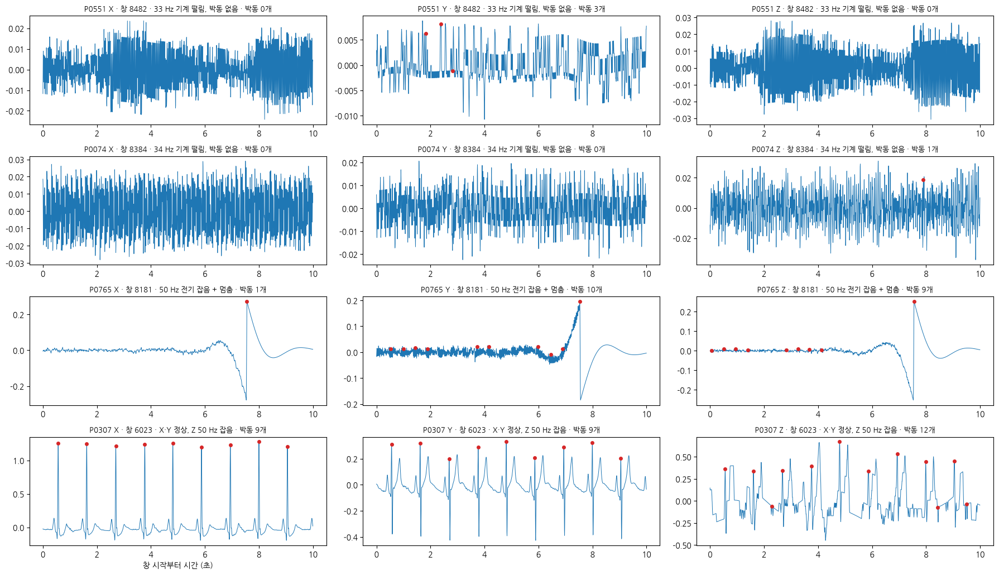

In [25]:
# 3-1 알고 있는 잡음 창에서 R파 검출기가 무엇을 잡는지
WIN_SEC = 10          # 1단계 판정 창 (초)
PAD_SEC = 60          # 앞뒤로 같이 읽어서 필터·검출하는 길이 (초)

CASES = [  # (환자, 10초 창 번호, 설명): 2단계 2-2와 같은 창
    ("P0551", 8482, "33 Hz 기계 떨림, 박동 없음"),
    ("P0074", 8384, "34 Hz 기계 떨림, 박동 없음"),
    ("P0765", 8181, "50 Hz 전기 잡음 + 멈춤"),
    ("P0307", 6023, "X·Y 정상, Z 50 Hz 잡음"),
]


def read_padded(pid, win_idx):
    """10초 창 + 앞뒤 1분을 mV로 읽음. 돌려주는 값: 유도 이름 목록, (샘플 수, 유도 수) 배열, 읽은 신호 안에서 10초 창이 시작하는 위치"""
    win, pad = WIN_SEC * FS, PAD_SEC * FS
    n_samples = wfdb.rdheader(str(HOLTER / pid)).sig_len      # 기록 전체 길이 (샘플)
    start = max(win_idx * win - pad, 0)                       # 기록 맨 앞이면 0부터
    end = min((win_idx + 1) * win + pad, n_samples)           # 기록 맨 끝이면 끝까지만
    rec = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16,
                        sampfrom=start, sampto=end)
    x_mv = rec.d_signal / np.asarray(rec.adc_gain)            # 정수 → mV
    return rec.sig_name, x_mv, win_idx * win - start


def detect_in_window(x_mv, offset):
    """앞뒤 1분까지 포함해서 R파용 필터 + 검출 → 가운데 10초 안의 R파 위치(10초 창 기준 샘플 번호)와 필터 후 10초 신호"""
    clean = r_filter(x_mv, FS)
    _, info = nk.ecg_peaks(clean, sampling_rate=FS, method="neurokit")
    peaks = np.asarray(info["ECG_R_Peaks"])
    win = WIN_SEC * FS
    inside = peaks[(peaks >= offset) & (peaks < offset + win)] - offset
    return inside, clean[offset:offset + win]


# ① 창마다 읽고, 유도마다 R파 검출
results = []
for pid, win_idx, desc in CASES:
    leads, x_mv, offset = read_padded(pid, win_idx)
    for j, lead in enumerate(leads):
        peaks, clean = detect_in_window(x_mv[:, j], offset)
        results.append({"환자": pid, "창": win_idx, "유도": lead, "설명": desc,
                        "박동 수": len(peaks), "심박수(bpm)": len(peaks) * 60 / WIN_SEC,
                        "peaks": peaks, "clean": clean})

# ② 표: 10초 안에 몇 개를 박동으로 잡았나 (정상 성인 안정 시 약 60~100 bpm = 10초에 10~17개)
table = pd.DataFrame(results).drop(columns=["peaks", "clean"])
display(table)

# ③ 그림: 창마다 한 줄, 유도마다 한 칸. 파랑 = R파용 필터 후 신호, 빨간 점 = 검출된 R파
t = np.arange(WIN_SEC * FS) / FS
n_rows, n_cols = len(CASES), 3                               # 유도는 최대 3개 (X·Y·Z)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 2.6 * n_rows), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")                                            # 유도가 2개뿐인 환자는 빈 칸
for r in results:
    row = [c[0] for c in CASES].index(r["환자"])
    col = "XYZ".index(r["유도"])
    ax = axes[row, col]
    ax.axis("on")
    ax.plot(t, r["clean"], color="tab:blue", lw=0.7)
    ax.plot(r["peaks"] / FS, r["clean"][r["peaks"]], "o", color="tab:red", ms=4)
    ax.set_title(f'{r["환자"]} {r["유도"]} · 창 {r["창"]} · {r["설명"]} · 박동 {r["박동 수"]}개', fontsize=9)
axes[-1, 0].set_xlabel("창 시작부터 시간 (초)")
plt.tight_layout()
plt.show()

### 3-1 결과

| 창 | 잡은 박동 (X / Y / Z) | 실제 | 심박수만 봤을 때 |
|---|---|---|---|
| P0551 · 33 Hz 떨림 | 0 / 3 / 0 | 박동 없음. Y의 3개는 2~3초에 몰린 잘못된 검출 | 0~18 bpm → 걸러짐 |
| P0074 · 34 Hz 떨림 | 0 / 0 / 1 | 박동 없음 | 0~6 bpm → 걸러짐 |
| P0765 · 50 Hz + 멈춤 | 1 / 10 / 9 | 박동 없음. 0 근처 잡음과 7.5초 멈춤 때의 필터 출렁임을 박동으로 착각 | 54~60 bpm → **정상처럼 보여 통과** ❌ |
| P0307 · X·Y 정상 | 9 / 9 / - | 빨간 점이 모두 실제 R파 위 | 54 bpm → 통과 ✅ |
| P0307 · Z 50 Hz | - / - / 12 | 9개는 X·Y와 같은 시각, 3개는 잡음 | 72 bpm → **통과** ❌ |

- **알게 된 것**: R파 검출기는 박동인지 판단하지 않고 뾰족한 곳을 찾을 뿐이다. 떨림 잡음은 박동을 거의 못 잡지만, 50 Hz 잡음에서는 가짜 박동을 정상 심박수만큼 잡는다 → **심박수만으로는 부족**하고, 두 검출기 일치·유도끼리 일치가 필요 (3-2)
- 잡음에서 잡힌 점의 높이는 약 0.01 mV, 정상 R파는 0.3~1.2 mV였다. 다만 R파 높이 기준은 저널 근거가 없어 쓰지 않음
- 신호가 멈추는 순간의 필터 출렁임(P0765 7.5초)도 박동으로 잡힌다 → 2단계 2-3의 "덩어리 끝 여유 3.5초"와 같은 현상
- **주의**: `read_padded`는 원본의 모든 유도를 읽음 (P0307 Z는 1단계에서 이미 제외된 유도). 3-4 전체 실행에서는 `record_qc.csv`의 유도 제외를 반영할 것
- **주의**: `RuntimeWarning: Mean of empty slice`는 박동이 0~1개인 창에서 neurokit2가 간격 평균을 내다 생기는 경고. 결과에는 영향 없음
- **한계**: 창 4개(잡음 3 + 정상 1)만 봄


## 3-2. 논문 확인 결과

- **원칙**: 저널 논문만. 원문 문장을 직접 읽은 것은 [전문], 초록만 본 것은 [초록], 다른 논문이 인용한 것만 본 것은 [2차]
- 판정값을 정하는 원조 논문 중 3편은 학교에서 받을 수 없음: Orphanidou 2015 (IEEE), Behar 2013 (IEEE), Caples 2007 본문 (JCSM). Li 2008 (IOP)은 저자 연구실 사본으로 확인

**논문 목록**

| 논문 | 데이터 | 우리에게 쓴 것 | 확인 | 관련성 |
|---|---|---|---|---|
| Li Q, Mark RG, Clifford GD. *Physiol Meas* 2008;29:15–32 ([저자 사본](https://web.archive.org/web/2015id_/http://lcp.mit.edu/pdf/LiPM08.pdf)) | 중환자실 심전도 | bSQI·iSQI 정의, 10초, 150 ms, 검출기 2개 | [전문] | 높음: bSQI 원조 |
| Li Q, Rajagopalan C, Clifford GD. *Comput Methods Programs Biomed* 2014;117:435–447 | MIT-BIH (홀터, 부정맥) | 검출기 2개, 잡음 단계 정의, 부정맥에서 정확도 하락 | [전문] | 높음: 데이터가 가장 가까움 |
| Steinberg JS 외. ISHNE-HRS 2017 expert consensus. *Ann Noninvasive Electrocardiol* 2017 ([PMC6931745](https://pmc.ncbi.nlm.nih.gov/articles/PMC6931745/)) | 홀터 지침 | 잡음은 여러 유도로 알아봄, 진짜 부정맥을 놓치면 더 위험 | [전문] | 높음: 홀터 공식 문서 |
| Zhao Z, Zhang Y. *Front Physiol* 2018;9:727 | 휴대용·12유도 짧은 기록 | bSQI 판정값 60% / 90% | [전문] | 중간 |
| *Sci Rep* 2025, textile electrodes ([PMC12639010](https://pmc.ncbi.nlm.nih.gov/articles/PMC12639010/)) | 환자 밤 심전도, 200 Hz, 15초 | 심박수 30~180 bpm | [전문] | 중간 |
| *Sensors* 2025;25:5186 ([PMC12390035](https://pmc.ncbi.nlm.nih.gov/articles/PMC12390035/)) | 건강한 20대 39명, 운동 | 10초 창 bSQI < 0.7, 심박수 30~240 bpm | [전문] | 중간~낮음 |
| AI-Holter VT. *Eur Heart J Digit Health* 2024 (doi 10.1093/ehjdh/ztae025) | 홀터 3유도 | bSQI > 0.8 (30분 창) | [전문] | 중간 |
| Clifford GD 외. *Physiol Meas* 2012;33:1419–1433 ([저자 사본](https://www.robots.ox.ac.uk/~gari/papers/IOP_ECG_SQI_Clifford_et_al.pdf)) | 12유도, MIT-BIH | 10초 창, 부정맥 데이터 93% | [전문] (투고본) | 중간 |
| Rahman S 외. *J R Soc Interface* 2022;19:20220012 | 공개 데이터 6종 | 첨도·주파수 비율을 빼는 근거 | [전문] | 중간 |
| Caples SM 외. *J Clin Sleep Med* 2007;3:147–154 | 수면 지침 | 수면 중 정상 서맥, 최대 2초 멈춤 | [초록] | 중간 |
| Gadaleta M 외. *npj Digit Med* 2023 | 장시간 패치 | 심박수 < 20 bpm 창 제외 (10분 창이라 참고만) | [전문] | 중간 |
| Vorreuther A 외. *Front Neuroergon* 2025;6:1585469 | 건강한 15명, PPG 기기 검증 | 박동 규칙(3초, 2.2) — 뺌 | [전문] | 낮음 |

**원문 문장**

| 논문 | 쪽 | 문장 |
|---|---|---|
| Li 2008 | 17 | "w is set to 10 s to be commensurate with the window over which the HR is calculated … and γ is set to be 150 ms as per the recommendations of the American National Standards Institute (ANSI/AAMI EC57 1998)." |
| Li 2008 | 18 | bSQI는 "if one QRS detection algorithm misses one or more beats (due to low QRS amplitudes) or registers extra beats (due to artifact or high amplitude T waves)" 이면 틀림 → iSQI(유도끼리 비교) |
| Li 2014 | 437 | Level 3: "Noise interferes with QRS or ventricular flutter recognition" / Level 4: "cannot be interpreted with confidence because of significant technical flaws" |
| Li 2014 | 446 | "it may be more judicious to apply rhythm detectors first, and then select an appropriate SQI combination pertinent to the suspected rhythm" |
| Zhao 2018 | 4 | qSQI = 2N/(Na+Nb): optimal > 90%, suspicious 60–90%, unqualified < 60% (이유 없음) |
| Sensors 2025 | 2.4절 | "an SQI value below 0.7 [25], mean heart rate below 30 bpm or above 240 bpm, or a mean heart rate difference in successive windows exceeding 10 bpm" |
| Sci Rep 2025 | 방법 | "The lower value was chosen as the minimum heart rate that can be expected during sleep and is 33 bpm" (Caples 2007 인용) |
| ISHNE-HRS 2017 | 3.2.6절 | "The majority of artifacts can be recognized from simultaneous multichannel ECG." |
| Caples 2007 | 초록 | "Asystoles of up to 2 seconds are seen in normal populations during sleep." |
| Rahman 2022 | 1 | "the fixed threshold-based SSQIs cannot be used as a robust noise detection system" |

**주의할 점**
- bSQI 계산식이 논문마다 다름: Li 2008 = 같이 찾은 박동 ÷ (둘 중 하나라도 찾은 박동), Zhao 2018 = 2 × 같이 찾은 박동 ÷ (두 검출기 박동 수 합), Li 2014 = wqrs 박동 중 eplimited도 찾은 비율. 판정값은 그 논문의 식과 같이 써야 함
- 판정값 0.6 / 0.7 / 0.8은 모두 우리와 다른 대상(휴대용, 운동, 30분 창)에서 정해짐 → 3-3에서 시험
- ②와 ③을 합치는 방법(심박수가 낮아도 유도끼리 맞으면 남김)은 논문에 있는 규칙이 아님 (✋)


## 3-3. 3-2 기준 시험

- **왜**: 3-2에서 고른 기준이 잡음은 버리고 정상·부정맥은 남기는지, 정답을 아는 창으로 확인한다
- **순서**: ① 묶음별 시험 창 뽑기 → ② 그림 → ③ 정답 표시 (Li 2014: 잡음이 QRS 인식을 방해하면 사용 불가) → ④ 기준 계산·비교
- **묶음**: 알려진 잡음 / 잡음 의심(1단계 버린 창 옆) / 동리듬 낮 / 동리듬 밤 / 심방세동·조동 / 조기박동 많음 / 페이스메이커
- 시각·상위 비율·창 수는 **뽑는 범위**일 뿐 판정 기준이 아님


In [26]:
# 3-3 ① 시험 창 고르기: 묶음별로 10초 창을 무작위로 뽑아 목록과 정답 기록표를 저장
SEED = 0                    # 무작위 고정 (다시 실행해도 같은 창이 뽑힘)
N_PER_GROUP = 15            # 묶음마다 뽑을 창 수 (환자 1명당 창 1개)
DAY_HOURS = (10, 20)        # 낮: 10시 이상 20시 미만 (뽑는 범위, 판정 기준 아님)
NIGHT_HOURS = (0, 5)        # 밤: 0시 이상 5시 미만
VPC_TOP_FRAC = 0.10         # 시간당 심실 조기박동 상위 10% 환자
SEC_PER_DAY = 24 * 3600
RHYTHM_SINUS, RHYTHM_AF, RHYTHM_PACED = [0], [1, 2], [3]   # 홀터 리듬 코드 (1단계와 같음)

TEST_DIR = OUT / "sqi_test"                  # 3단계 시험 결과 폴더
TEST_DIR.mkdir(exist_ok=True)
LABEL_PATH = TEST_DIR / "labels.csv"         # 정답 기록표
rng = np.random.default_rng(SEED)


# ① 환자 정보: 1단계 결과 + 홀터 시작 시각 + 시간당 심실 조기박동
def onset_seconds(text):
    """'11:8:39' 같은 시작 시각 → 0시부터 몇 초인지. 비어 있으면 NaN"""
    if pd.isna(text):
        return np.nan
    h, m, s = (int(v) for v in str(text).strip("' ").split(":"))
    return h * 3600 + m * 60 + s


def comma_number(column):
    """'112,5'처럼 소수점이 쉼표인 글자 → 숫자"""
    return pd.to_numeric(column.astype(str).str.replace(",", "."), errors="coerce")


info = pd.read_csv(ROOT / "data" / "music" / "subject-info.csv", sep=";")
info.columns = info.columns.str.strip()
info = pd.DataFrame({
    "pid": info["Patient ID"],
    "onset_s": info["Holter onset (hh:mm:ss)"].map(onset_seconds),
    "vpc_per_h": comma_number(info["Number of ventricular premature contractions per hour"]),
})
pat = qc_pass.merge(info, on="pid", how="left").set_index("pid")
print("시작 시각 있는 환자:", pat["onset_s"].notna().sum(), "/", len(pat))


# ② 창 하나하나의 상태: 1단계 판정과 시각
def window_flags(pid):
    """1단계 창 판정 → (남은 유도 모두 깨끗한 창, 시작 구간이 아닌 이유로 버린 창)"""
    z = np.load(WIN_DIR / f"{pid}.npz")
    rows = [list(z["leads"]).index(lead) for lead in pat.at[pid, "leads"]]   # 1단계에서 남은 유도만
    clean = ~z["bad"][rows].any(axis=0)
    bad_mid = (z["bad"][rows] & ~z["start"][rows]).any(axis=0)
    return clean, bad_mid


def window_hour(pid, win_idx):
    """창의 시각 (0~24시). 창 번호는 하나여도, 배열이어도 됨. 시작 시각이 없으면 NaN"""
    seconds = pat.at[pid, "onset_s"] + np.asarray(win_idx) * WIN_SEC
    return (seconds % SEC_PER_DAY) / 3600


def in_hours(hour, hours):
    """시각이 (시작, 끝) 범위 안인지"""
    return (hour >= hours[0]) & (hour < hours[1])


# ③ 묶음별 "뽑아도 되는 창" 조건 (환자 한 명 → 창마다 True/False)
def clean_any_time(pid):
    """깨끗한 창 전부"""
    clean, _ = window_flags(pid)
    return clean


def clean_daytime(pid):
    """깨끗하면서 낮 시간대인 창"""
    clean, _ = window_flags(pid)
    return clean & in_hours(window_hour(pid, np.arange(len(clean))), DAY_HOURS)


def clean_nighttime(pid):
    """깨끗하면서 밤 시간대인 창"""
    clean, _ = window_flags(pid)
    return clean & in_hours(window_hour(pid, np.arange(len(clean))), NIGHT_HOURS)


def next_to_bad(pid):
    """깨끗하지만 바로 앞이나 뒤 창을 1단계에서 버린 창"""
    clean, bad_mid = window_flags(pid)
    neighbor = np.zeros_like(bad_mid)
    neighbor[1:] |= bad_mid[:-1]          # 앞 창이 버려짐
    neighbor[:-1] |= bad_mid[1:]          # 뒤 창이 버려짐
    return clean & neighbor


# ④ 묶음 정의: 묶음 이름 → (뽑을 환자, 창 조건)
rhythm = pat["holter_rhythm"]
sinus = pat.index[rhythm.isin(RHYTHM_SINUS)]
sinus_with_onset = sinus.intersection(pat.index[pat["onset_s"].notna()])
many_vpc = pat.index[pat["vpc_per_h"] >= pat["vpc_per_h"].quantile(1 - VPC_TOP_FRAC)]

GROUPS = {
    "잡음 의심": (pat.index, next_to_bad),
    "동리듬 낮": (sinus_with_onset, clean_daytime),
    "동리듬 밤": (sinus_with_onset, clean_nighttime),
    "심방세동·조동": (pat.index[rhythm.isin(RHYTHM_AF)], clean_any_time),
    "조기박동 많음": (sinus.intersection(many_vpc), clean_any_time),
    "페이스메이커": (pat.index[rhythm.isin(RHYTHM_PACED)], clean_any_time),
}


# ⑤ 뽑기: 환자를 무작위 순서로 돌며 조건에 맞는 창을 하나씩
def pick_windows(group, pids, is_candidate):
    """조건에 맞는 창이 있는 환자에게서 창 1개씩, N_PER_GROUP개가 모이면 멈춤"""
    rows = []
    for pid in rng.permutation(np.asarray(pids)):
        candidates = np.flatnonzero(is_candidate(pid))
        if len(candidates) == 0:
            continue
        rows.append({"group": group, "pid": pid, "win_idx": int(rng.choice(candidates))})
        if len(rows) == N_PER_GROUP:
            break
    return rows


rows = [{"group": "알려진 잡음", "pid": pid, "win_idx": win} for pid, win, _ in CASES]
for group, (pids, is_candidate) in GROUPS.items():
    rows += pick_windows(group, pids, is_candidate)

test_windows = pd.DataFrame(rows)
test_windows.insert(0, "test_id", range(len(test_windows)))     # 그림·정답표에서 쓰는 번호
test_windows["leads"] = test_windows["pid"].map(pat["leads"])
test_windows["rhythm"] = test_windows["pid"].map(rhythm)
test_windows["hour"] = [window_hour(pid, win) for pid, win in zip(test_windows["pid"], test_windows["win_idx"])]
test_windows.to_csv(TEST_DIR / "test_windows.csv", index=False, encoding="utf-8-sig")
display(test_windows.groupby("group", sort=False).size().rename("창 수").to_frame())


# ⑥ 정답 기록표: 창 × 유도마다 한 줄. 이미 있으면 덮어쓰지 않음 (적어 둔 정답 보호)
if LABEL_PATH.exists():
    print("정답 기록표가 이미 있어서 그대로 둠:", LABEL_PATH)
else:
    label_rows = []
    for w in test_windows.itertuples():
        for lead in w.leads:
            label_rows.append({"test_id": w.test_id, "group": w.group, "pid": w.pid,
                               "win_idx": w.win_idx, "lead": lead, "usable": ""})
    pd.DataFrame(label_rows).to_csv(LABEL_PATH, index=False, encoding="utf-8-sig")
    print("정답 기록표 저장:", LABEL_PATH, "/", len(label_rows), "줄")


시작 시각 있는 환자: 517 / 708


,창 수
group,
알려진 잡음,4
잡음 의심,15
동리듬 낮,15
동리듬 밤,15
심방세동·조동,15
조기박동 많음,15
페이스메이커,15


정답 기록표가 이미 있어서 그대로 둠: /home/mingyu/poc-test/results/preprocess/sqi_test/labels.csv


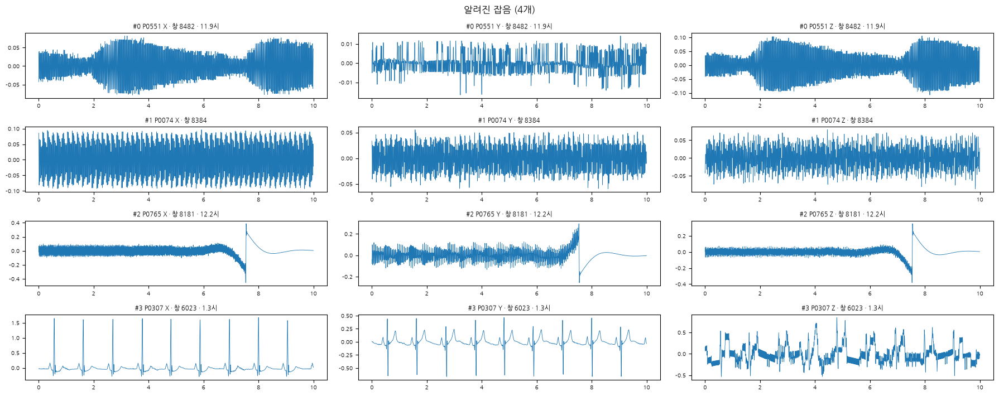

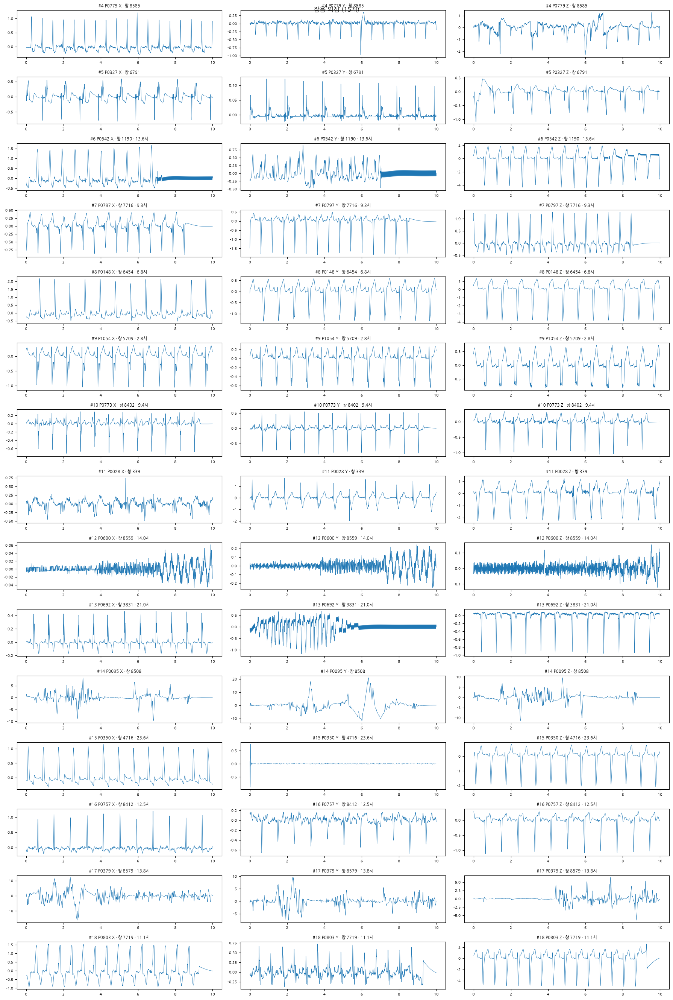

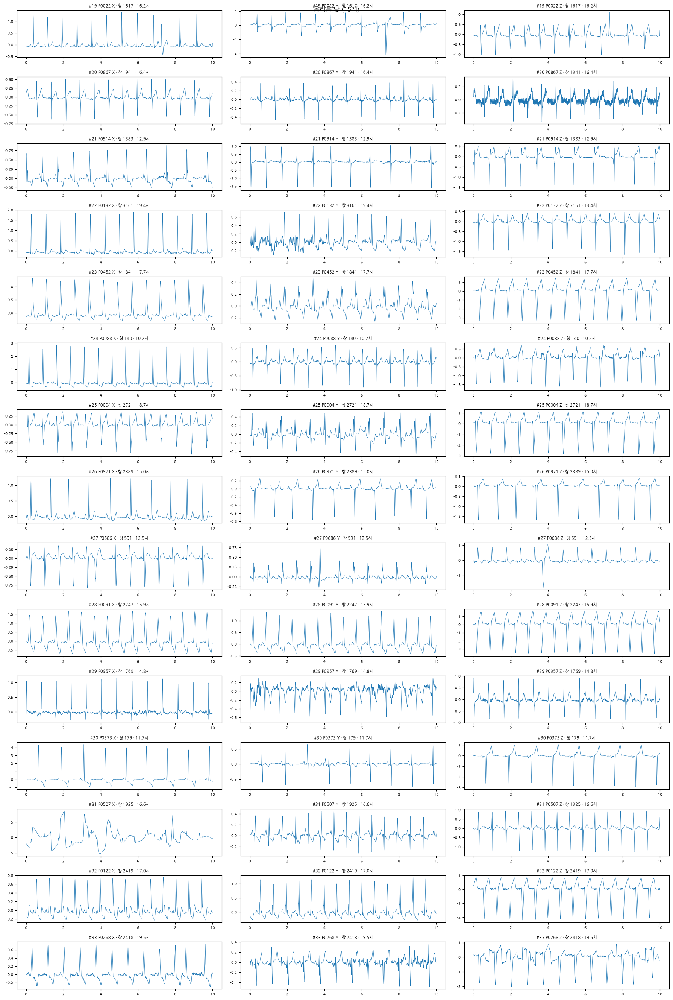

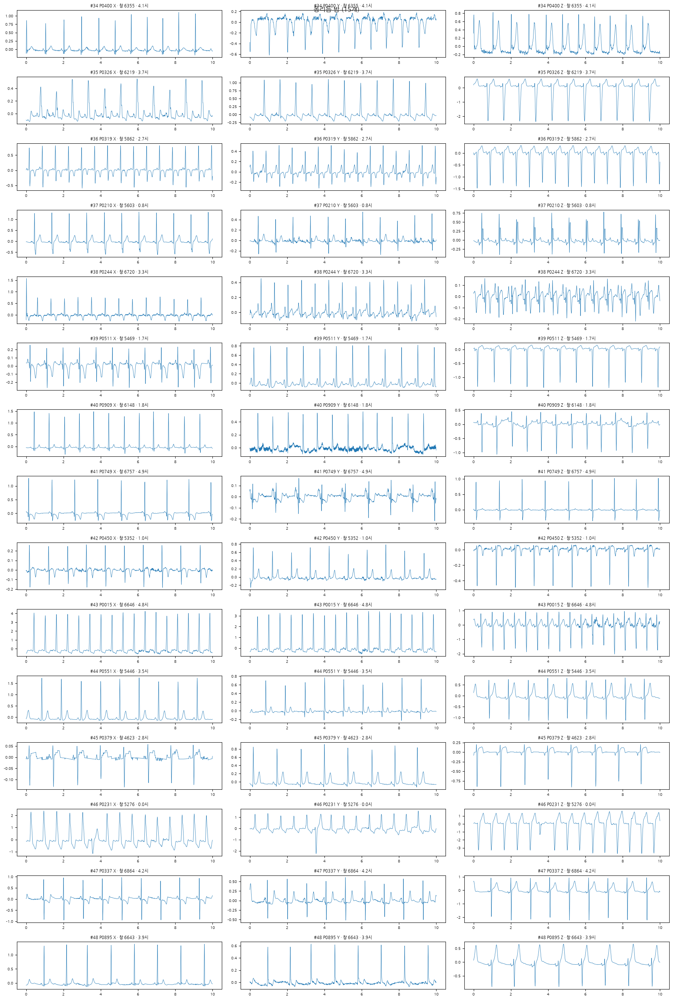

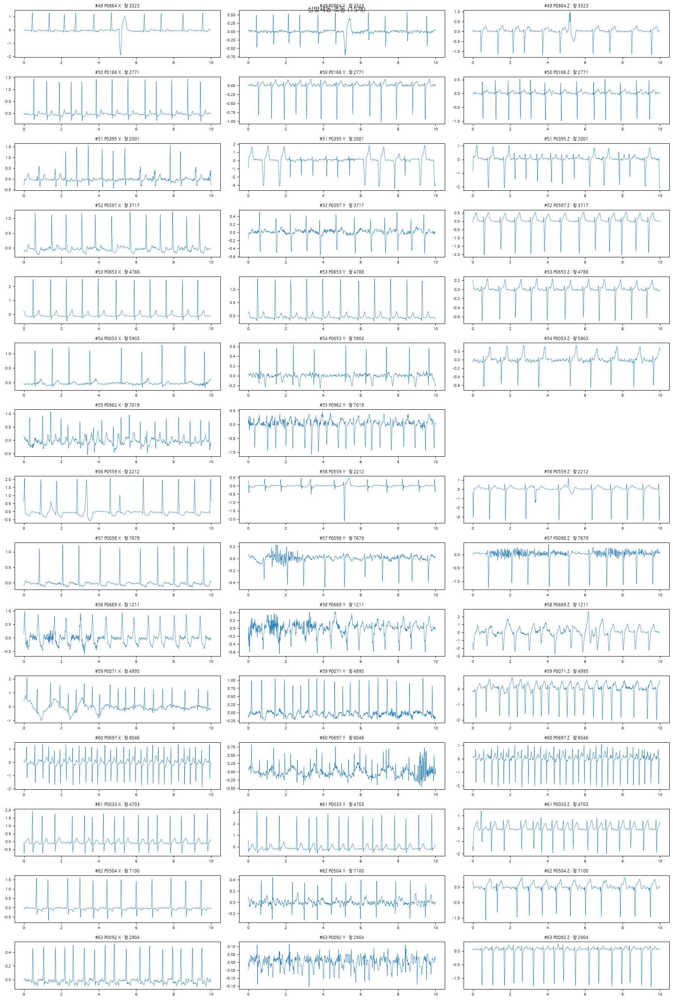

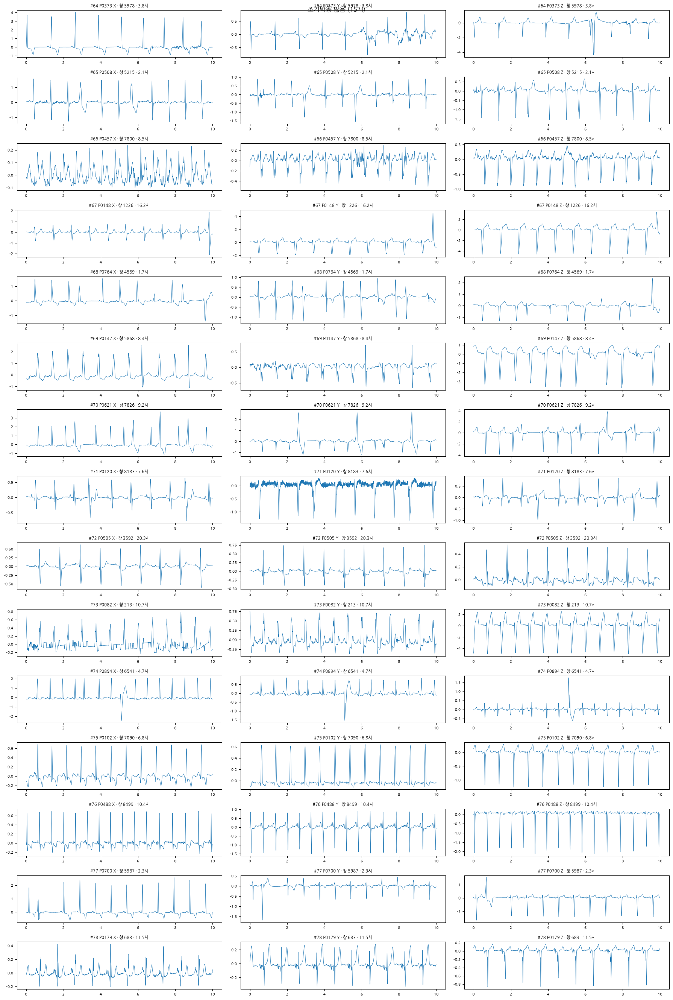

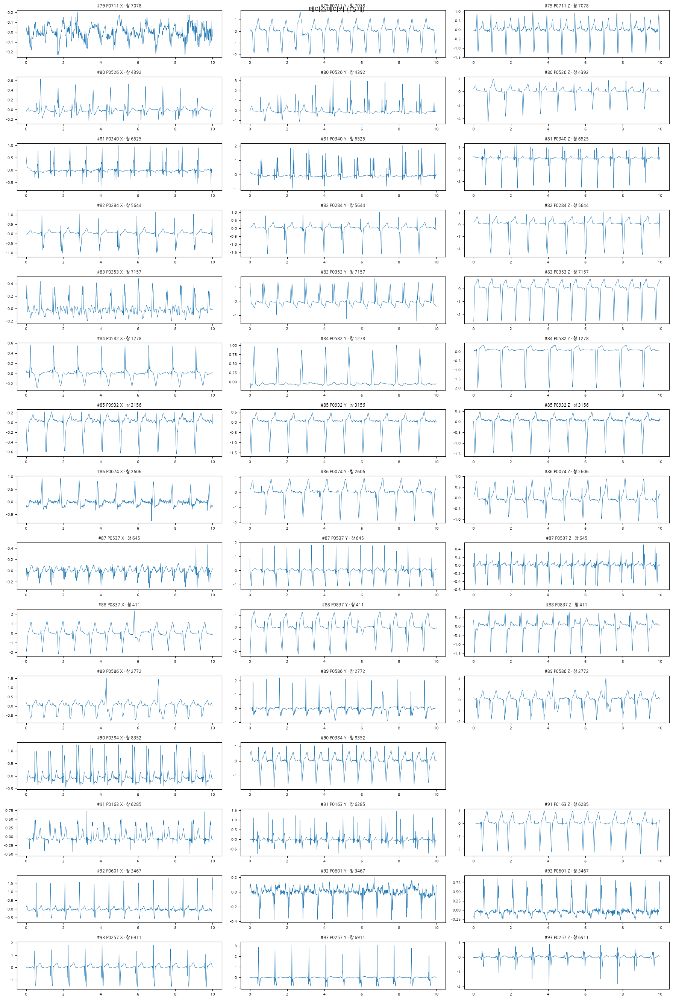

In [27]:
# 3-3 ② 시험 창 그림: 묶음마다 1장. 한 줄 = 창 하나, 한 칸 = 유도 하나 (DL 입력용 필터 후)
LEAD_ORDER = "XYZ"
ROW_HEIGHT_IN = 1.8           # 그림 한 줄 높이 (인치)


def read_window_dl(pid, win_idx):
    """10초 창을 앞뒤 1분과 같이 읽어 DL 필터를 건 뒤 가운데 10초만 → (유도 이름, (샘플, 유도) 배열)"""
    leads, x_mv, offset = read_padded(pid, win_idx)
    filtered = np.column_stack([dl_filter(x_mv[:, j], FS) for j in range(x_mv.shape[1])])
    return leads, filtered[offset:offset + WIN_SEC * FS]


def plot_group(group, windows):
    """한 묶음의 창들을 그려 PNG로 저장하고 화면에 표시"""
    t = np.arange(WIN_SEC * FS) / FS
    fig, axes = plt.subplots(len(windows), len(LEAD_ORDER), squeeze=False,
                             figsize=(18, ROW_HEIGHT_IN * len(windows)))
    for ax in axes.ravel():
        ax.axis("off")                                         # 없는 유도는 빈 칸
    for row, w in enumerate(windows.itertuples()):
        leads, signal = read_window_dl(w.pid, w.win_idx)
        for j, lead in enumerate(leads):
            if lead not in w.leads:                            # 1단계에서 제외된 유도는 안 그림
                continue
            ax = axes[row, LEAD_ORDER.index(lead)]
            ax.axis("on")
            ax.plot(t, signal[:, j], color="tab:blue", lw=0.6)
            hour = "" if pd.isna(w.hour) else f" · {w.hour:.1f}시"
            ax.set_title(f"#{w.test_id} {w.pid} {lead} · 창 {w.win_idx}{hour}", fontsize=8)
            ax.tick_params(labelsize=7)
    fig.suptitle(f"{group} ({len(windows)}개)", fontsize=12)
    plt.tight_layout()
    fig.savefig(TEST_DIR / f"windows_{group}.png", dpi=80)
    plt.show()


for group, windows in test_windows.groupby("group", sort=False):
    plot_group(group, windows)


In [28]:
# 3-3 ④ 기준 계산: 유도마다 bSQI(두 식) · 심박수 · iSQI를 구하고 정답과 비교
DETECTORS = ("neurokit", "elgendi2010")      # Kristof 2024 최상위 + 모양 변화에 안정적 (Porr 2024). 짝 선택은 ✋
MATCH_SEC = 0.150                           # 같은 박동으로 보는 허용 오차 (Li 2008, ANSI/AAMI EC57)
BSQI_THRESHOLDS = (0.6, 0.7, 0.8)           # Zhao 2018 / Sensors 2025 / EHJ-DH 2024 (시험할 후보)
HR_LOW_BPM = 30                             # 이보다 느리면 의심 (Sci Rep 2025, Sensors 2025)
STRICT_MIN_BAD, MAJORITY_MIN_BAD = 1, 3     # 정답: 나쁜 2초 칸이 이 수 이상이면 사용 불가
RESULT_PATH = TEST_DIR / "criteria_scores.csv"


# ① R파 찾기: 앞뒤 1분과 같이 읽어 필터 → 검출기별 R파 위치(가운데 10초 기준, 초 단위)
def find_peaks(clean, offset, method):
    """검출기 하나로 R파를 찾고 가운데 10초 안의 것만 → 10초 창 기준 시각(초) 배열. 실패하면 빈 배열"""
    try:
        peaks = np.asarray(nk.ecg_findpeaks(clean, sampling_rate=FS, method=method)["ECG_R_Peaks"])
    except Exception:
        return np.array([])
    inside = peaks[(peaks >= offset) & (peaks < offset + WIN_SEC * FS)]
    return (inside - offset) / FS


def peaks_by_lead(pid, win_idx):
    """창 하나의 유도마다 {검출기: R파 시각} → {유도: {...}}"""
    leads, x_mv, offset = read_padded(pid, win_idx)
    result = {}
    for j, lead in enumerate(leads):
        clean = r_filter(x_mv[:, j], FS)
        result[lead] = {m: find_peaks(clean, offset, m) for m in DETECTORS}
    return result


# ② 두 박동 목록 맞춰 보기
def count_matched(a, b, tol=MATCH_SEC):
    """a와 b에서 tol초 안에 짝이 되는 박동 수 (하나는 한 번만 짝지음)"""
    i = j = matched = 0
    while i < len(a) and j < len(b):
        if abs(a[i] - b[j]) <= tol:
            matched, i, j = matched + 1, i + 1, j + 1
        elif a[i] < b[j]:
            i += 1
        else:
            j += 1
    return matched


def bsqi_li2008(a, b):
    """같이 찾은 박동 ÷ 둘 중 하나라도 찾은 박동. 박동이 하나도 없으면 0"""
    n = count_matched(a, b)
    total = len(a) + len(b) - n
    return n / total if total else 0.0


def bsqi_zhao2018(a, b):
    """2 × 같이 찾은 박동 ÷ 두 검출기 박동 수의 합. 박동이 하나도 없으면 0"""
    total = len(a) + len(b)
    return 2 * count_matched(a, b) / total if total else 0.0


def isqi(lead, peaks):
    """이 유도 박동과 다른 유도 박동의 일치(Li 2008 식) 중 가장 높은 값. 다른 유도가 없으면 NaN"""
    main = DETECTORS[0]                                       # 주 검출기 (neurokit)
    own = peaks[lead][main]
    others = [bsqi_li2008(own, peaks[o][main]) for o in peaks if o != lead]
    return max(others) if others else np.nan


# ③ 시험 창 전체 계산 (1단계에서 남은 유도만)
labels = pd.read_csv(LABEL_PATH)
rows = []
for w in test_windows.itertuples():
    peaks = peaks_by_lead(w.pid, w.win_idx)
    peaks = {lead: p for lead, p in peaks.items() if lead in w.leads}
    for lead, p in peaks.items():
        ham, zong = p["neurokit"], p["elgendi2010"]
        rows.append({"test_id": w.test_id, "lead": lead,
                     "n_hamilton": len(ham), "n_zong": len(zong),
                     "hr_bpm": len(ham) * 60 / WIN_SEC,
                     "bsqi_li": bsqi_li2008(ham, zong), "bsqi_zhao": bsqi_zhao2018(ham, zong),
                     "isqi": isqi(lead, peaks)})
scores = labels.merge(pd.DataFrame(rows), on=["test_id", "lead"], how="left")
scores.to_csv(RESULT_PATH, index=False, encoding="utf-8-sig")
print("저장:", RESULT_PATH, "/", len(scores), "줄")


# ④ 정답과 비교: 끊김 창은 빼고, 판정값마다 '잡음 잡은 비율'과 '정상 남긴 비율'
def compare(table, truth_min_bad, score_col):
    """판정값마다 [잡음을 잡음으로 / 사용 가능을 남김] 비율 표"""
    unusable = table["n_bad_2s"] >= truth_min_bad
    out = []
    for thr in BSQI_THRESHOLDS:
        flagged = table[score_col] < thr
        out.append({"판정값": thr,
                    "잡음 잡음": f"{(flagged & unusable).sum()}/{unusable.sum()}",
                    "정상 남김": f"{(~flagged & ~unusable).sum()}/{(~unusable).sum()}"})
    return pd.DataFrame(out)


tested = scores[scores["cut"] == 0]
for name, table in [("전체 정답", tested), ("애매한 것 뺀 정답", tested[tested["unsure"] == 0])]:
    for score_col in ("bsqi_li", "bsqi_zhao"):
        print(f"\n[{name} · 엄격 · {score_col}]")
        display(compare(table, STRICT_MIN_BAD, score_col))
print("\n[전체 정답 · 다수결 · bsqi_li]")
display(compare(tested, MAJORITY_MIN_BAD, "bsqi_li"))


# ⑤ 묶음별로: 판정값 0.6~0.8에서 정상(사용 가능) 유도를 몇 개 버리나 + 심박수 30 미만 수
usable = tested[tested["n_bad_2s"] < STRICT_MIN_BAD]
by_group = pd.DataFrame({f"bSQI<{t} 버림": usable.groupby("group", sort=False)["bsqi_li"].apply(lambda s: (s < t).sum())
                         for t in BSQI_THRESHOLDS})
by_group["심박수<30"] = usable.groupby("group", sort=False)["hr_bpm"].apply(lambda s: (s < HR_LOW_BPM).sum())
by_group["사용 가능 유도 수"] = usable.groupby("group", sort=False).size()
display(by_group)


/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


저장: /home/mingyu/poc-test/results/preprocess/sqi_test/criteria_scores.csv / 280 줄

[전체 정답 · 엄격 · bsqi_li]


,판정값,잡음 잡음,정상 남김
0,0.6,25/31,101/234
1,0.7,27/31,83/234
2,0.8,28/31,74/234



[전체 정답 · 엄격 · bsqi_zhao]


,판정값,잡음 잡음,정상 남김
0,0.6,19/31,143/234
1,0.7,25/31,115/234
2,0.8,27/31,92/234


...


[애매한 것 뺀 정답 · 엄격 · bsqi_zhao]


,판정값,잡음 잡음,정상 남김
0,0.6,16/22,129/212
1,0.7,22/22,106/212
2,0.8,22/22,85/212



[전체 정답 · 다수결 · bsqi_li]


,판정값,잡음 잡음,정상 남김
0,0.6,22/24,105/241
1,0.7,22/24,85/241
2,0.8,23/24,76/241


,bSQI<0.6 버림,bSQI<0.7 버림,bSQI<0.8 버림,심박수<30,사용 가능 유도 수
group,,,,,
알려진 잡음,0,0,0,0,2
잡음 의심,14,16,17,2,21
동리듬 낮,22,25,25,0,42
동리듬 밤,28,32,33,0,45
심방세동·조동,20,24,26,0,39
조기박동 많음,27,28,31,3,43
페이스메이커,22,26,28,5,42


위치 어긋남 후보: 46 개 / 두 번 세기 후보: 50 개


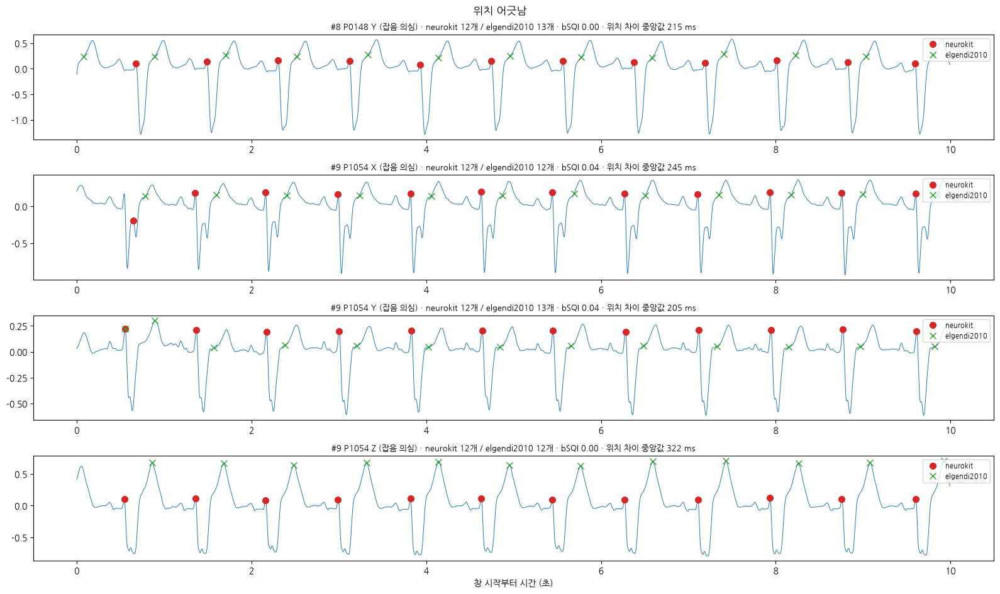

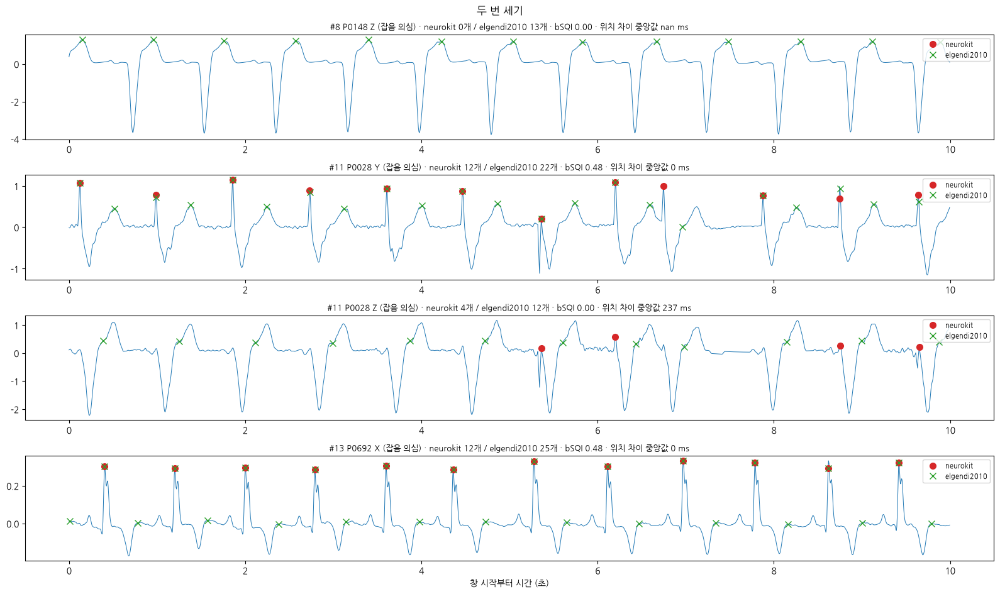

In [29]:
# 3-3 ⑤ 원인 확인: 정상인데 bSQI가 낮은 유도에서 두 검출기가 어디를 짚었나 (규칙은 바꾸지 않음)
N_PER_KIND = 4              # 종류마다 그릴 유도 수
OFFSET_MAX_BSQI = 0.3       # '위치 어긋남' 후보: bSQI가 이보다 낮음 (그림 고르는 범위일 뿐)
DOUBLE_RATIO = 1.5          # '두 번 세기' 후보: Elgendi 박동 수 ≥ neurokit × 이 값
MAIN, SECOND = DETECTORS    # ("neurokit", "elgendi2010")


# ① 그릴 유도 고르기: 정상(사용 가능, 끊김 아님) 중에서 두 종류
normal = scores[(scores["cut"] == 0) & (scores["n_bad_2s"] == 0)]
same_count = (normal["n_hamilton"] - normal["n_zong"]).abs() <= 1
offset_cases = normal[same_count & (normal["bsqi_li"] < OFFSET_MAX_BSQI)].head(N_PER_KIND)
double_cases = normal[normal["n_zong"] >= DOUBLE_RATIO * normal["n_hamilton"]].head(N_PER_KIND)
print("위치 어긋남 후보:", same_count.sum() and len(normal[same_count & (normal["bsqi_li"] < OFFSET_MAX_BSQI)]), "개",
      "/ 두 번 세기 후보:", len(normal[normal["n_zong"] >= DOUBLE_RATIO * normal["n_hamilton"]]), "개")


# ② 한 유도의 신호와 두 검출기 위치
def lead_signal_and_peaks(pid, win_idx, lead):
    """R파용 필터를 건 가운데 10초 신호와 검출기별 R파 시각(초)"""
    leads, x_mv, offset = read_padded(pid, win_idx)
    clean = r_filter(x_mv[:, leads.index(lead)], FS)
    peaks = {m: find_peaks(clean, offset, m) for m in DETECTORS}
    return clean[offset:offset + WIN_SEC * FS], peaks


def median_gap_ms(a, b):
    """a의 박동마다 b에서 가장 가까운 박동까지 거리(ms)의 중앙값. 부호: b가 늦으면 +"""
    if len(a) == 0 or len(b) == 0:
        return np.nan
    gaps = [b[np.argmin(np.abs(b - t))] - t for t in a]
    return np.median(gaps) * 1000


# ③ 그림: 한 줄에 유도 하나. 빨간 점 = neurokit, 초록 × = Elgendi
def plot_cases(cases, kind):
    """고른 유도들을 그려서 저장"""
    if len(cases) == 0:
        print(kind, ": 해당 유도 없음")
        return
    t = np.arange(WIN_SEC * FS) / FS
    fig, axes = plt.subplots(len(cases), 1, figsize=(16, 2.4 * len(cases)), squeeze=False)
    for ax, r in zip(axes[:, 0], cases.itertuples()):
        signal, peaks = lead_signal_and_peaks(r.pid, r.win_idx, r.lead)
        ax.plot(t, signal, color="tab:blue", lw=0.7)
        for method, style in [(MAIN, dict(marker="o", color="tab:red")), (SECOND, dict(marker="x", color="tab:green"))]:
            idx = (peaks[method] * FS).astype(int)
            ax.plot(peaks[method], signal[idx], ls="none", ms=7, label=method, **style)
        gap = median_gap_ms(peaks[MAIN], peaks[SECOND])
        ax.set_title(f"#{r.test_id} {r.pid} {r.lead} ({r.group}) · {MAIN} {len(peaks[MAIN])}개 / "
                     f"{SECOND} {len(peaks[SECOND])}개 · bSQI {r.bsqi_li:.2f} · 위치 차이 중앙값 {gap:.0f} ms", fontsize=9)
        ax.legend(loc="upper right", fontsize=8)
    axes[-1, 0].set_xlabel("창 시작부터 시간 (초)")
    fig.suptitle(kind, fontsize=12)
    plt.tight_layout()
    fig.savefig(TEST_DIR / f"diagnose_{kind}.png", dpi=80)
    plt.show()


plot_cases(offset_cases, "위치 어긋남")
plot_cases(double_cases, "두 번 세기")


뒤집은 유도 수: {'X': {'sum': 18, 'count': 89}, 'Y': {'sum': 38, 'count': 89}, 'Z': {'sum': 77, 'count': 87}}


/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


저장: /home/mingyu/poc-test/results/preprocess/sqi_test/criteria_scores_inverted.csv

[뒤집기 전 · 엄격 · bsqi_li]


,판정값,잡음 잡음,정상 남김
0,0.6,25/31,101/234
1,0.7,27/31,83/234
2,0.8,28/31,74/234



[뒤집기 후 · 엄격 · bsqi_li]


,판정값,잡음 잡음,정상 남김
0,0.6,24/31,132/234
1,0.7,28/31,107/234
2,0.8,28/31,93/234



[뒤집기 후 · 애매한 것 뺀 정답 · bsqi_li]


,판정값,잡음 잡음,정상 남김
0,0.6,20/22,116/212
1,0.7,22/22,96/212
2,0.8,22/22,85/212


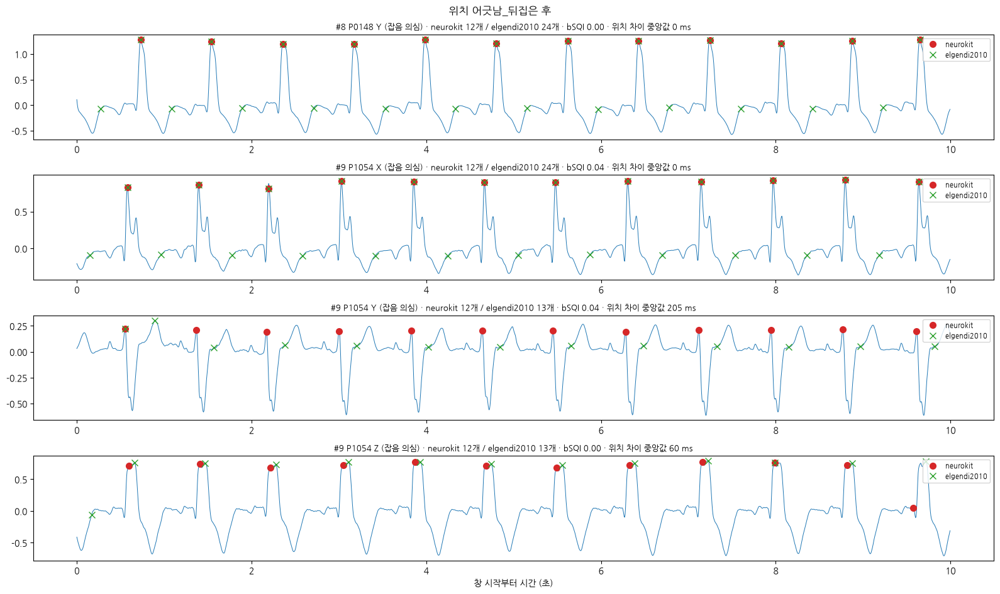

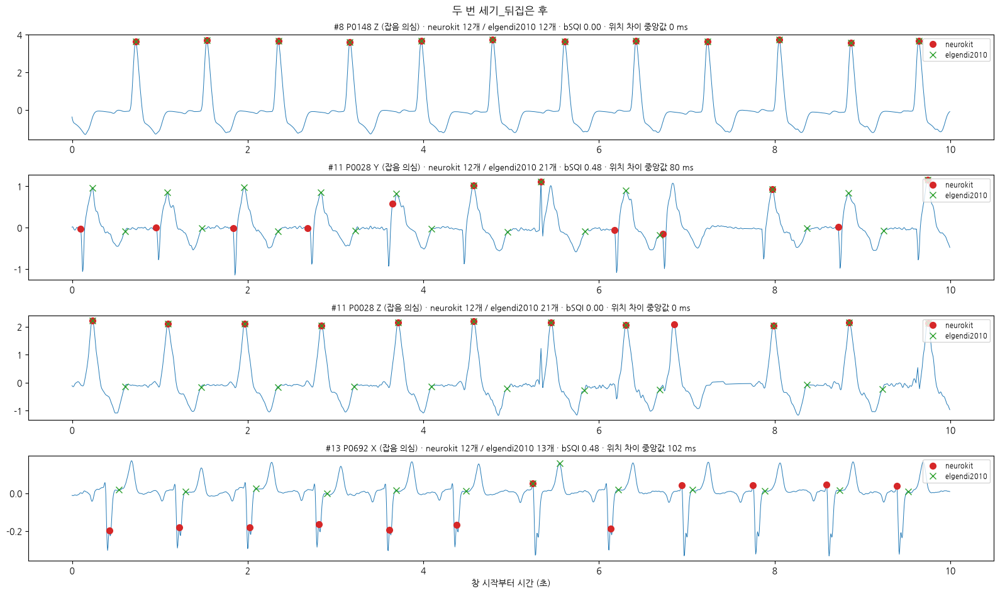

In [30]:
# 3-3 ⑥ 극성 보정 후 다시 계산: QRS가 아래로 향한 유도는 검출 직전에만 위아래를 뒤집음 (✋, 도구: nk.ecg_invert)
N_POLARITY_WINDOWS = 12     # 방향을 판단할 깨끗한 10초 창 수 (기록 전체에 고르게). 판정 기준 아님
RESULT_INV_PATH = TEST_DIR / "criteria_scores_inverted.csv"
POLARITY_PATH = TEST_DIR / "lead_polarity.csv"


# ① 환자·유도마다 방향 정하기 (기록 전체에서 한 번)
def read_window_raw(pid, win_idx):
    """10초 창 하나를 mV로 읽음 → (유도 이름, (샘플, 유도) 배열)"""
    start = win_idx * WIN_SEC * FS
    rec = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16,
                        sampfrom=start, sampto=start + WIN_SEC * FS)
    return rec.sig_name, rec.d_signal / np.asarray(rec.adc_gain)


def spread_clean_windows(pid, n):
    """깨끗한 창 중 기록 전체에 고르게 퍼진 n개의 창 번호"""
    clean, _ = window_flags(pid)
    candidates = np.flatnonzero(clean)
    picks = np.linspace(0, len(candidates) - 1, min(n, len(candidates))).astype(int)
    return candidates[picks]


def lead_polarity(pid):
    """유도마다 뒤집을지 → {유도: True/False}. 깨끗한 창 n개에서 '아래로 향함' 판정이 과반이면 True"""
    votes = {lead: [] for lead in pat.at[pid, "leads"]}
    for win_idx in spread_clean_windows(pid, N_POLARITY_WINDOWS):
        names, x_mv = read_window_raw(pid, win_idx)
        for lead in votes:
            _, inverted = nk.ecg_invert(x_mv[:, names.index(lead)], sampling_rate=FS)
            votes[lead].append(inverted)
    return {lead: np.mean(v) > 0.5 for lead, v in votes.items()}


polarity = {pid: lead_polarity(pid) for pid in test_windows["pid"].unique()}
polarity_table = pd.DataFrame([{"pid": pid, "lead": lead, "inverted": inv}
                               for pid, leads in polarity.items() for lead, inv in leads.items()])
polarity_table.to_csv(POLARITY_PATH, index=False, encoding="utf-8-sig")
print("뒤집은 유도 수:", polarity_table.groupby("lead")["inverted"].agg(["sum", "count"]).to_dict("index"))


# ② 극성 보정을 넣어 다시 계산 (나머지는 ④와 같음)
def peaks_by_lead_inverted(pid, win_idx):
    """④의 peaks_by_lead와 같되, 뒤집기로 정한 유도는 검출 전에 부호를 바꿈"""
    leads, x_mv, offset = read_padded(pid, win_idx)
    result = {}
    for j, lead in enumerate(leads):
        clean = r_filter(x_mv[:, j], FS)
        if polarity[pid].get(lead, False):
            clean = -clean
        result[lead] = {m: find_peaks(clean, offset, m) for m in DETECTORS}
    return result


rows = []
for w in test_windows.itertuples():
    peaks = {lead: p for lead, p in peaks_by_lead_inverted(w.pid, w.win_idx).items() if lead in w.leads}
    for lead, p in peaks.items():
        first, second = p[MAIN], p[SECOND]
        rows.append({"test_id": w.test_id, "lead": lead, "inverted": polarity[w.pid][lead],
                     "n_main": len(first), "n_second": len(second),
                     "hr_bpm": len(first) * 60 / WIN_SEC,
                     "bsqi_li": bsqi_li2008(first, second), "bsqi_zhao": bsqi_zhao2018(first, second),
                     "isqi": isqi(lead, peaks)})
scores_inv = labels.merge(pd.DataFrame(rows), on=["test_id", "lead"], how="left")
scores_inv.to_csv(RESULT_INV_PATH, index=False, encoding="utf-8-sig")
print("저장:", RESULT_INV_PATH)


# ③ 뒤집기 전(④) vs 후 비교 (엄격 정답, 끊김 제외)
before = scores[scores["cut"] == 0]
after = scores_inv[scores_inv["cut"] == 0]
for name, table in [("뒤집기 전", before), ("뒤집기 후", after)]:
    print(f"\n[{name} · 엄격 · bsqi_li]")
    display(compare(table, STRICT_MIN_BAD, "bsqi_li"))
print("\n[뒤집기 후 · 애매한 것 뺀 정답 · bsqi_li]")
display(compare(after[after["unsure"] == 0], STRICT_MIN_BAD, "bsqi_li"))


# ④ 확인 그림: ⑤에서 본 같은 유도를 뒤집은 뒤 다시 그림
def lead_signal_and_peaks(pid, win_idx, lead):
    """⑤와 같되 극성 보정 적용"""
    leads, x_mv, offset = read_padded(pid, win_idx)
    clean = r_filter(x_mv[:, leads.index(lead)], FS)
    if polarity[pid].get(lead, False):
        clean = -clean
    peaks = {m: find_peaks(clean, offset, m) for m in DETECTORS}
    return clean[offset:offset + WIN_SEC * FS], peaks


plot_cases(offset_cases, "위치 어긋남_뒤집은 후")
plot_cases(double_cases, "두 번 세기_뒤집은 후")


/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/mingyu/poc-test/.venv/lib/python3.12/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


저장: /home/mingyu/poc-test/results/preprocess/sqi_test/criteria_scores_cleanfix.csv

[④ 처음 · 엄격 · bsqi_li]


,판정값,잡음 잡음,정상 남김
0,0.6,25/31,101/234
1,0.7,27/31,83/234
2,0.8,28/31,74/234



[⑥ 극성 보정 · 엄격 · bsqi_li]


,판정값,잡음 잡음,정상 남김
0,0.6,24/31,132/234
1,0.7,28/31,107/234
2,0.8,28/31,93/234



[⑦ 전용 전처리 · 엄격 · bsqi_li]


,판정값,잡음 잡음,정상 남김
0,0.6,18/31,220/234
1,0.7,21/31,217/234
2,0.8,22/31,211/234



[⑦ · 애매한 것 뺀 정답 · bsqi_li]


,판정값,잡음 잡음,정상 남김
0,0.6,17/22,199/212
1,0.7,19/22,196/212
2,0.8,19/22,191/212


정상 유도 중 Elgendi 박동 수가 neurokit의 1.5배 이상: 1 / 234


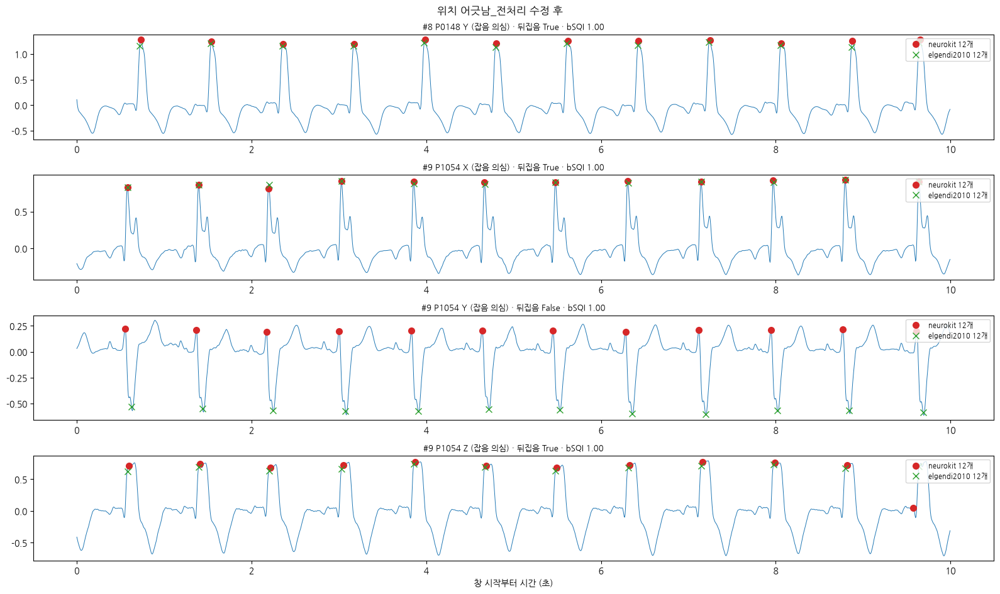

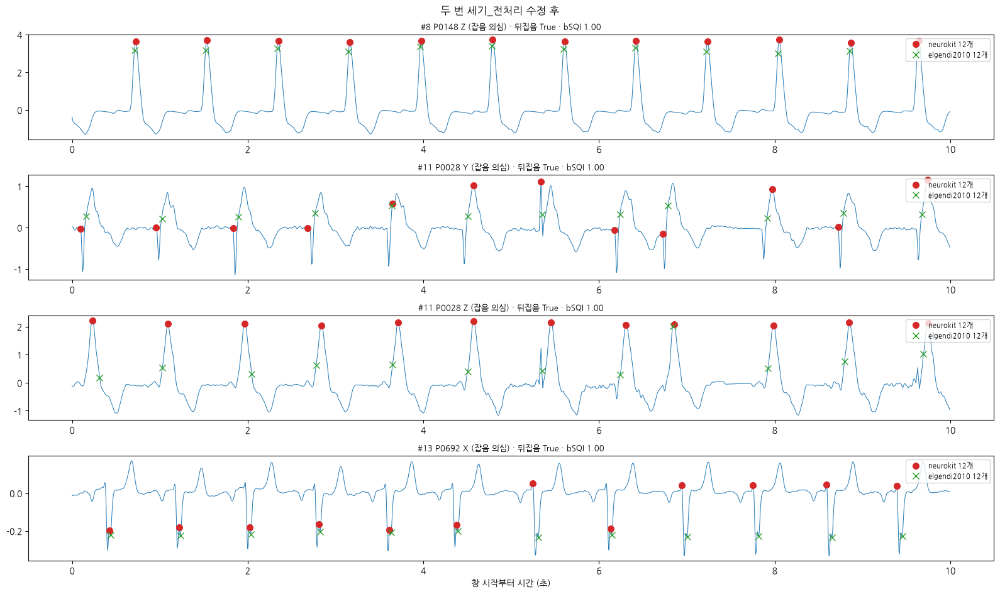

In [31]:
# 3-3 ⑦ 검출기마다 전용 전처리로 다시 계산 (극성 보정은 ⑥ 그대로)
CLEAN_METHOD = {"neurokit": "neurokit", "elgendi2010": "elgendi2010"}   # 검출기 이름 → neurokit2 전용 전처리
RESULT_FIX_PATH = TEST_DIR / "criteria_scores_cleanfix.csv"


# ① 검출기마다 자기 전처리를 걸고 R파 찾기
def peaks_by_lead_cleanfix(pid, win_idx):
    """유도마다 (극성 보정) → 검출기별 전용 전처리 → 검출 → {유도: {검출기: R파 시각}}"""
    leads, x_mv, offset = read_padded(pid, win_idx)
    result = {}
    for j, lead in enumerate(leads):
        raw = -x_mv[:, j] if polarity[pid].get(lead, False) else x_mv[:, j]
        result[lead] = {}
        for m in DETECTORS:
            clean = nk.ecg_clean(raw, sampling_rate=FS, method=CLEAN_METHOD[m])
            result[lead][m] = find_peaks(clean, offset, m)
    return result


# ② 시험 창 전체 다시 계산 (나머지는 ⑥과 같음)
rows = []
for w in test_windows.itertuples():
    peaks = {lead: p for lead, p in peaks_by_lead_cleanfix(w.pid, w.win_idx).items() if lead in w.leads}
    for lead, p in peaks.items():
        first, second = p[MAIN], p[SECOND]
        rows.append({"test_id": w.test_id, "lead": lead, "inverted": polarity[w.pid][lead],
                     "n_main": len(first), "n_second": len(second),
                     "hr_bpm": len(first) * 60 / WIN_SEC,
                     "bsqi_li": bsqi_li2008(first, second), "bsqi_zhao": bsqi_zhao2018(first, second),
                     "isqi": isqi(lead, peaks)})
scores_fix = labels.merge(pd.DataFrame(rows), on=["test_id", "lead"], how="left")
scores_fix.to_csv(RESULT_FIX_PATH, index=False, encoding="utf-8-sig")
print("저장:", RESULT_FIX_PATH)


# ③ 단계별 비교 (엄격 정답, 끊김 제외)
for name, table in [("④ 처음", scores), ("⑥ 극성 보정", scores_inv), ("⑦ 전용 전처리", scores_fix)]:
    print(f"\n[{name} · 엄격 · bsqi_li]")
    display(compare(table[table["cut"] == 0], STRICT_MIN_BAD, "bsqi_li"))
fixed = scores_fix[scores_fix["cut"] == 0]
print("\n[⑦ · 애매한 것 뺀 정답 · bsqi_li]")
display(compare(fixed[fixed["unsure"] == 0], STRICT_MIN_BAD, "bsqi_li"))

normal_fix = fixed[fixed["n_bad_2s"] == 0]
print("정상 유도 중 Elgendi 박동 수가 neurokit의 1.5배 이상:",
      (normal_fix["n_second"] >= DOUBLE_RATIO * normal_fix["n_main"]).sum(), "/", len(normal_fix))


# ④ 확인 그림: ⑤와 같은 유도. 제목의 bSQI는 이번 결과에서 가져옴
def plot_cases_fix(cases, kind):
    """⑤의 plot_cases와 같되, 검출기별 전용 전처리 + 새 bSQI"""
    t = np.arange(WIN_SEC * FS) / FS
    fig, axes = plt.subplots(len(cases), 1, figsize=(16, 2.4 * len(cases)), squeeze=False)
    for ax, r in zip(axes[:, 0], cases.itertuples()):
        leads, x_mv, offset = read_padded(r.pid, r.win_idx)
        raw = x_mv[:, leads.index(r.lead)]
        raw = -raw if polarity[r.pid].get(r.lead, False) else raw
        shown = nk.ecg_clean(raw, sampling_rate=FS, method=CLEAN_METHOD[MAIN])[offset:offset + WIN_SEC * FS]
        ax.plot(t, shown, color="tab:blue", lw=0.7)
        for method, style in [(MAIN, dict(marker="o", color="tab:red")), (SECOND, dict(marker="x", color="tab:green"))]:
            clean = nk.ecg_clean(raw, sampling_rate=FS, method=CLEAN_METHOD[method])
            p = find_peaks(clean, offset, method)
            ax.plot(p, shown[(p * FS).astype(int)], ls="none", ms=7, label=f"{method} {len(p)}개", **style)
        new = scores_fix[(scores_fix["test_id"] == r.test_id) & (scores_fix["lead"] == r.lead)]["bsqi_li"].iloc[0]
        ax.set_title(f"#{r.test_id} {r.pid} {r.lead} ({r.group}) · 뒤집음 {polarity[r.pid][r.lead]} · bSQI {new:.2f}", fontsize=9)
        ax.legend(loc="upper right", fontsize=8)
    axes[-1, 0].set_xlabel("창 시작부터 시간 (초)")
    fig.suptitle(kind, fontsize=12)
    plt.tight_layout()
    fig.savefig(TEST_DIR / f"diagnose_{kind}.png", dpi=80)
    plt.show()


plot_cases_fix(offset_cases, "위치 어긋남_전처리 수정 후")
plot_cases_fix(double_cases, "두 번 세기_전처리 수정 후")


시험용에 쓴 환자: 89 명 → 이번에는 제외


,창 수
group,
잡음 의심,15
동리듬 낮,15
동리듬 밤,15
심방세동·조동,15
조기박동 많음,15
페이스메이커,15


정답 기록표가 이미 있어서 그대로 둠: /home/mingyu/poc-test/results/preprocess/sqi_test/holdout_labels.csv


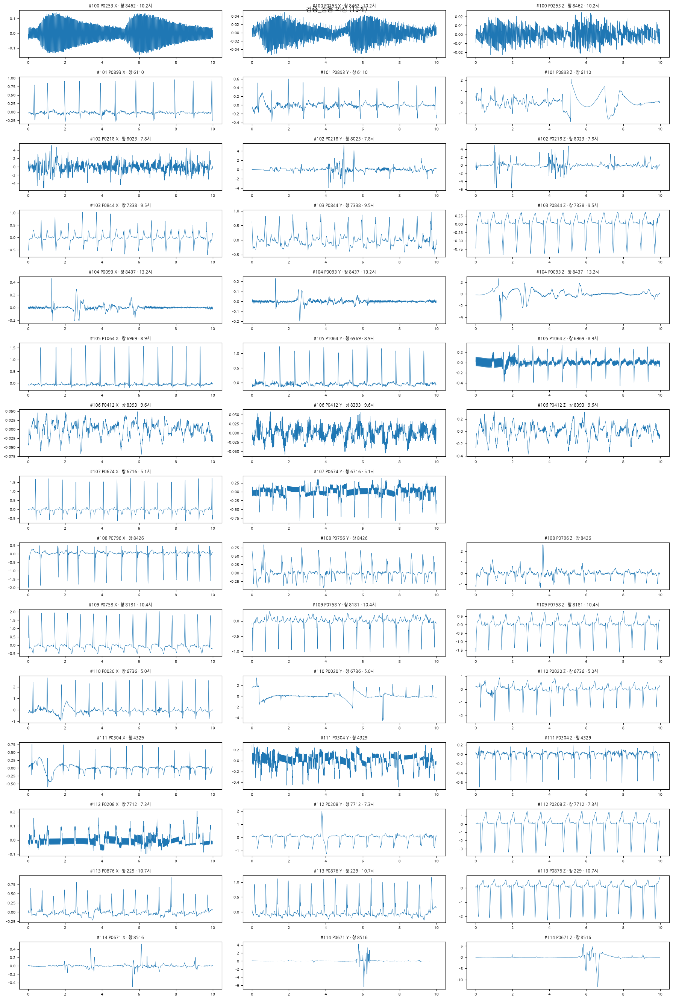

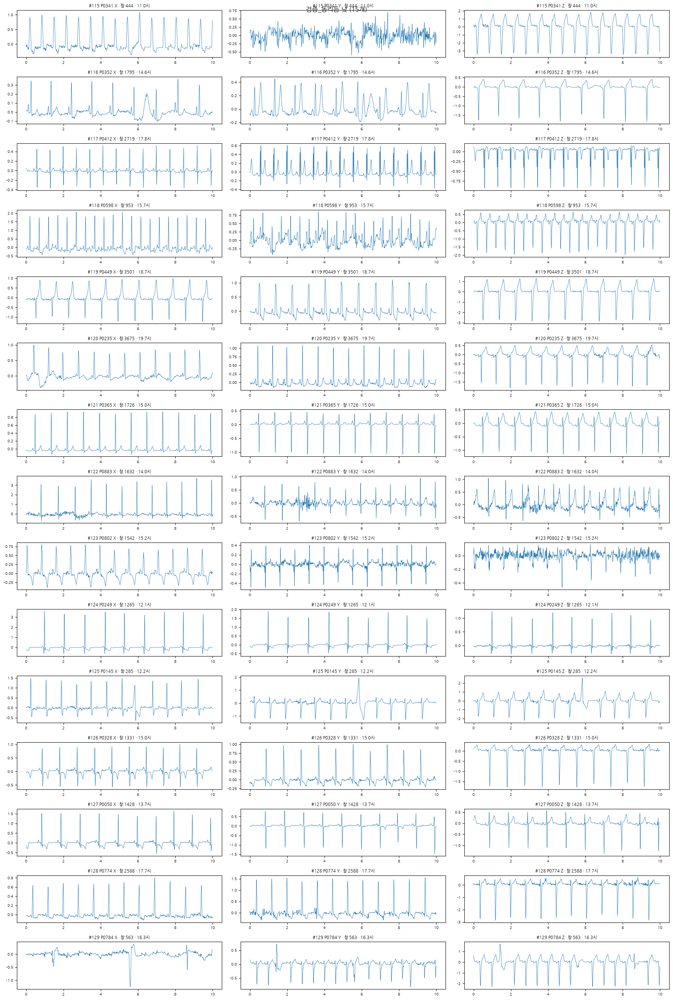

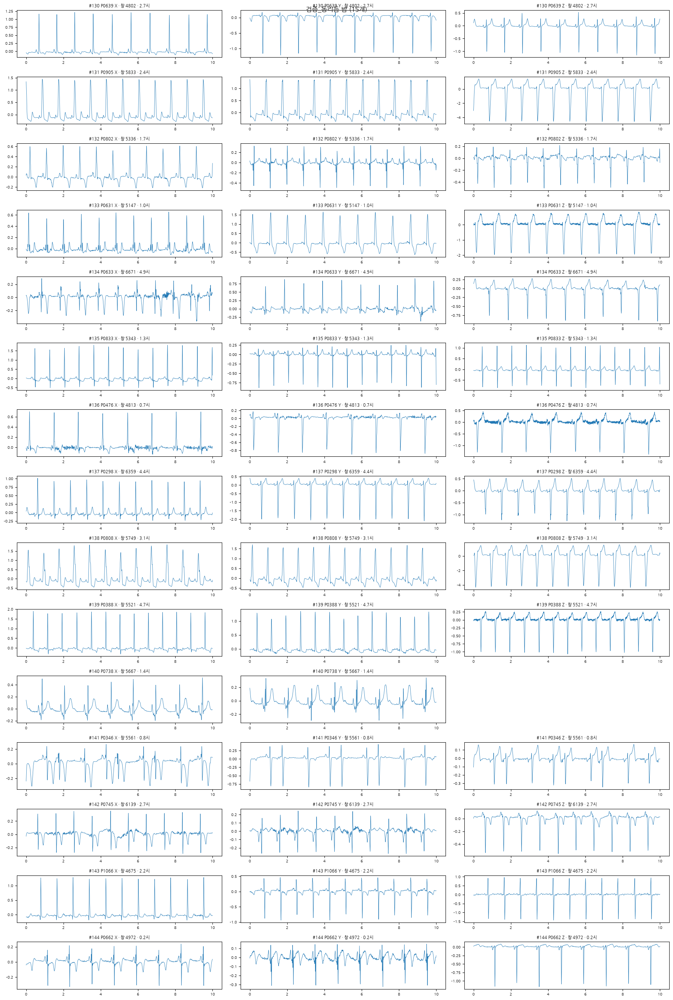

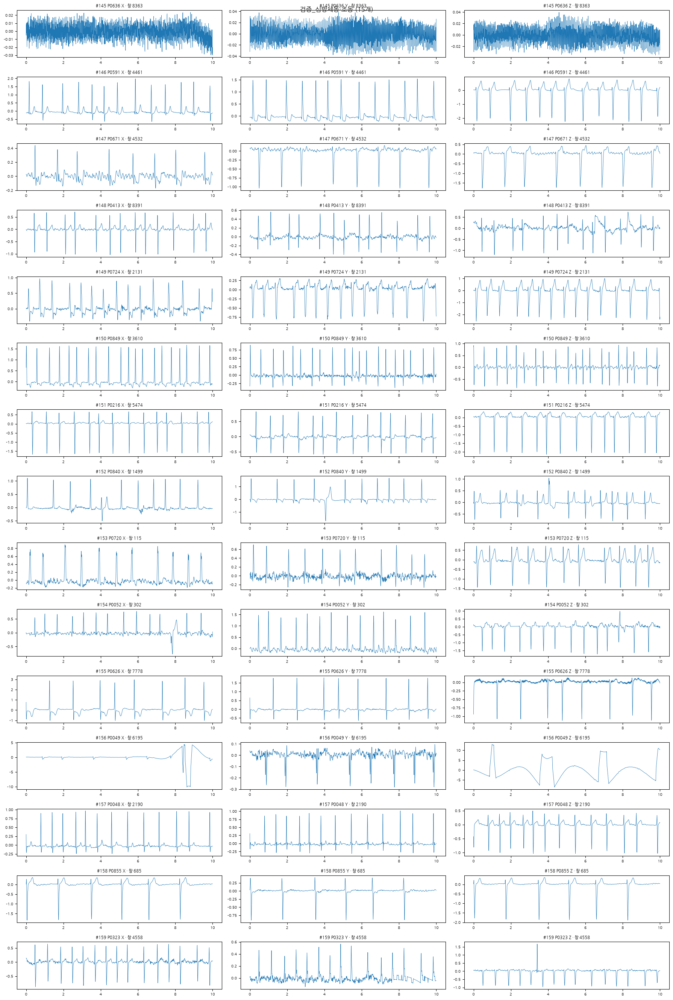

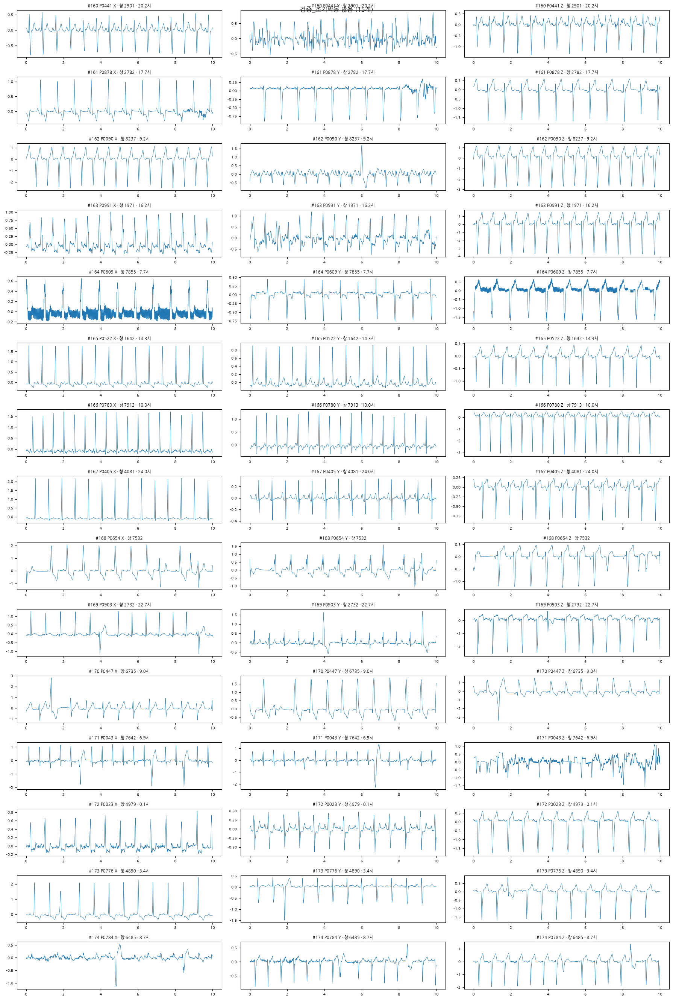

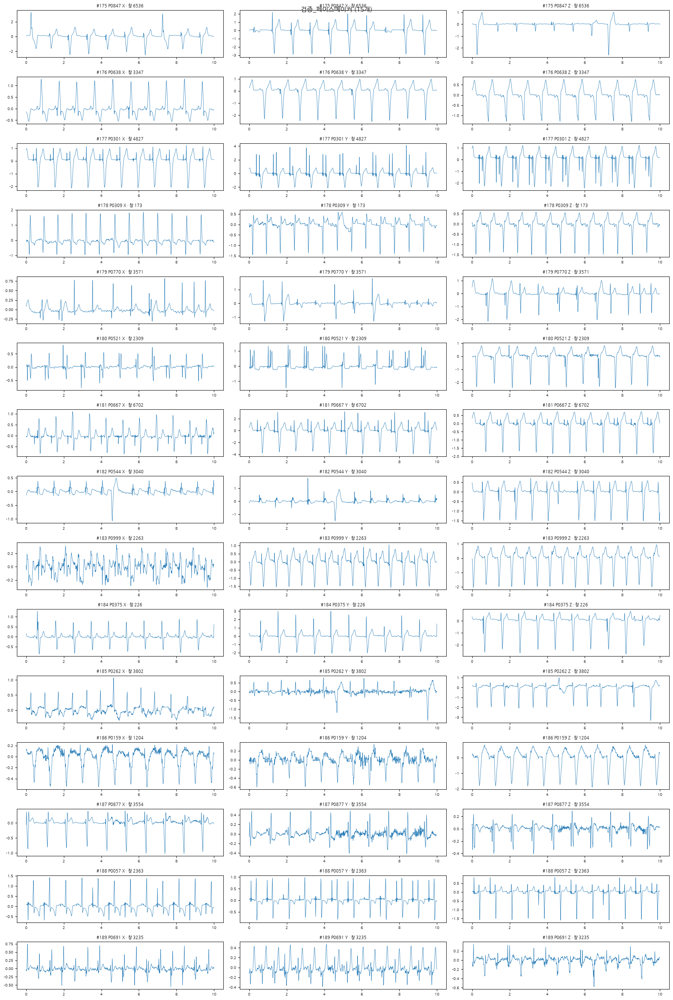

In [32]:
# 3-3 ⑧ 최종 확인용 새 창 뽑기: ①~⑦에 안 쓴 환자에서, 같은 묶음 규칙으로 (정답을 먼저 매기고 점수는 나중에)
HOLDOUT_SEED = 1            # ①(SEED 0)과 다른 무작위 → 다른 창
HOLDOUT_FIRST_ID = 100      # 시험용(0~93)과 번호가 겹치지 않게 100번부터
HOLDOUT_PREFIX = "검증_"     # 그림 파일 이름 앞에 붙임 (시험용 그림 덮어쓰기 방지)
HOLDOUT_WINDOWS_PATH = TEST_DIR / "holdout_windows.csv"
HOLDOUT_LABEL_PATH = TEST_DIR / "holdout_labels.csv"


# ① 시험용 94개 창에 쓴 환자는 빼기
used_pids = set(pd.read_csv(TEST_DIR / "test_windows.csv")["pid"])
print("시험용에 쓴 환자:", len(used_pids), "명 → 이번에는 제외")


# ② 묶음별로 새로 뽑기 (①의 묶음 규칙·pick_windows 그대로, 난수만 새로)
rng = np.random.default_rng(HOLDOUT_SEED)       # pick_windows가 쓰는 난수를 새 값으로
rows = []
for group, (pids, is_candidate) in GROUPS.items():
    fresh = pd.Index(pids).difference(list(used_pids))
    rows += pick_windows(group, fresh, is_candidate)

holdout = pd.DataFrame(rows)
holdout.insert(0, "test_id", range(HOLDOUT_FIRST_ID, HOLDOUT_FIRST_ID + len(holdout)))
holdout["leads"] = holdout["pid"].map(pat["leads"])
holdout["rhythm"] = holdout["pid"].map(rhythm)
holdout["hour"] = [window_hour(pid, win) for pid, win in zip(holdout["pid"], holdout["win_idx"])]
holdout.to_csv(HOLDOUT_WINDOWS_PATH, index=False, encoding="utf-8-sig")
display(holdout.groupby("group", sort=False).size().rename("창 수").to_frame())


# ③ 정답 기록표: 창 × 유도마다 한 줄, 칸은 비워 둠. 이미 있으면 덮어쓰지 않음
if HOLDOUT_LABEL_PATH.exists():
    print("정답 기록표가 이미 있어서 그대로 둠:", HOLDOUT_LABEL_PATH)
else:
    label_rows = [{"test_id": w.test_id, "group": w.group, "pid": w.pid, "win_idx": w.win_idx,
                   "lead": lead, "cut": "", "n_bad_2s": "", "unsure": "", "note": ""}
                  for w in holdout.itertuples() for lead in w.leads]
    pd.DataFrame(label_rows).to_csv(HOLDOUT_LABEL_PATH, index=False, encoding="utf-8-sig")
    print("정답 기록표 저장:", HOLDOUT_LABEL_PATH, "/", len(label_rows), "줄")

# ④ 그림: 정답 매기기용 (②의 plot_group 그대로, 파일 이름만 '검증_' 붙임)
for group, windows in holdout.groupby("group", sort=False):
    plot_group(HOLDOUT_PREFIX + group, windows)


In [33]:
# 3-3 ⑨ 최종 확인: 미리 고정한 규칙으로 새 창을 한 번만 채점 (이 결과를 보고 규칙을 바꾸지 않음)
FINAL_BSQI = 0.6                      # 잡음 판정: bSQI(Li 2008) < 0.6 또는 심박수 < 30
PASS_KEEP, PASS_CATCH = 0.90, 0.70    # 합격선 ✋ (논문 근거 없음, 결과 보기 전에 정함)
HOLDOUT_SCORE_PATH = TEST_DIR / "holdout_scores.csv"


# ① 새 환자의 유도 방향 정하기 (⑥의 lead_polarity 그대로)
for pid in holdout["pid"].unique():
    if pid not in polarity:
        polarity[pid] = lead_polarity(pid)


# ② 점수 계산 (⑦의 peaks_by_lead_cleanfix 그대로)
holdout_labels = pd.read_csv(HOLDOUT_LABEL_PATH)
rows = []
for w in holdout.itertuples():
    peaks = {lead: p for lead, p in peaks_by_lead_cleanfix(w.pid, w.win_idx).items() if lead in w.leads}
    for lead, p in peaks.items():
        first, second = p[MAIN], p[SECOND]
        rows.append({"test_id": w.test_id, "lead": lead, "inverted": polarity[w.pid][lead],
                     "n_main": len(first), "n_second": len(second),
                     "hr_bpm": len(first) * 60 / WIN_SEC,
                     "bsqi_li": bsqi_li2008(first, second)})
final = holdout_labels.merge(pd.DataFrame(rows), on=["test_id", "lead"], how="left")
final["flagged"] = (final["bsqi_li"] < FINAL_BSQI) | (final["hr_bpm"] < HR_LOW_BPM)
final.to_csv(HOLDOUT_SCORE_PATH, index=False, encoding="utf-8-sig")
print("저장:", HOLDOUT_SCORE_PATH)


# ③ 합격 확인: 깨끗함 통과 비율(전체 깨끗한 유도) · 잡음 잡은 비율(확실한 잡음)
def pass_rates(table):
    """(깨끗함 통과 개수, 깨끗한 유도 수, 잡음 잡은 개수, 잡음 유도 수)"""
    noisy = table["n_bad_2s"] >= STRICT_MIN_BAD
    return ((~table["flagged"] & ~noisy).sum(), (~noisy).sum(),
            (table["flagged"] & noisy).sum(), noisy.sum())


tested = final[final["cut"] == 0]
summary = []
for name, table in [("전체 정답", tested), ("확실한 정답만", tested[tested["unsure"] == 0])]:
    kept, n_clean, caught, n_noisy = pass_rates(table)
    summary.append({"정답": name, "깨끗함 통과": f"{kept}/{n_clean} ({kept / n_clean:.0%})",
                    "잡음 잡음": f"{caught}/{n_noisy} ({caught / n_noisy:.0%})"})
display(pd.DataFrame(summary))

kept, n_clean, _, _ = pass_rates(tested)
_, _, caught, n_noisy = pass_rates(tested[tested["unsure"] == 0])
print(f"합격선: 깨끗함 통과 {kept / n_clean:.0%} (≥{PASS_KEEP:.0%}) / 확실한 잡음 잡기 {caught / n_noisy:.0%} (≥{PASS_CATCH:.0%})",
      "→ 합격" if kept / n_clean >= PASS_KEEP and caught / n_noisy >= PASS_CATCH else "→ 불합격")


# ④ 깨끗한데 버려진 유도: 묶음별 개수 (SCD 쏠림 확인용)
wrongly_dropped = tested[(tested["n_bad_2s"] == 0) & tested["flagged"]]
display(wrongly_dropped.groupby("group", sort=False).size().rename("깨끗한데 버림").to_frame())


저장: /home/mingyu/poc-test/results/preprocess/sqi_test/holdout_scores.csv


,정답,깨끗함 통과,잡음 잡음
0,전체 정답,214/231 (93%),19/37 (51%)
1,확실한 정답만,198/214 (93%),13/18 (72%)


합격선: 깨끗함 통과 93% (≥90%) / 확실한 잡음 잡기 72% (≥70%) → 합격


,깨끗한데 버림
group,
동리듬 낮,2
동리듬 밤,1
심방세동·조동,5
조기박동 많음,1
페이스메이커,8


In [34]:
# 3-4 ① 전체 실행 준비: 환자 기록 전체를 한 번에 검출 → 10초 창마다 bSQI·심박수 → 환자별 저장
FINAL_BSQI = 0.6                  # ⑨에서 확정한 판정값 (bSQI < 0.6 또는 심박수 < 30 → 그 유도 잡음)
FULL_DIR = OUT / "sqi_full"       # 환자별 결과 폴더 (환자 1명 = npz 1개)
FULL_DIR.mkdir(exist_ok=True)
N_TRIAL = 5                       # 먼저 시험할 환자 수 (⑨ 새 창 환자 중에서)


# ① 한 유도 전체에서 R파 찾기 (⑦과 같은 검출기별 전용 전처리)
def peaks_full(x_mv, method):
    """기록 전체 한 유도 → R파 위치(샘플 번호). 실패하면 빈 배열"""
    clean = nk.ecg_clean(x_mv, sampling_rate=FS, method=CLEAN_METHOD[method])
    try:
        return np.asarray(nk.ecg_findpeaks(clean, sampling_rate=FS, method=method)["ECG_R_Peaks"])
    except Exception:
        return np.array([], dtype=int)


def split_by_window(peaks, n_win):
    """R파 위치(샘플) → 창마다 '창 시작부터 몇 초' 배열의 목록"""
    win = WIN_SEC * FS
    window_of_peak = peaks // win                                   # R파마다 몇 번째 창에 있는지
    starts = np.searchsorted(window_of_peak, np.arange(n_win + 1))  # 창마다 첫 R파가 목록의 몇 번째인지
    return [(peaks[starts[k]:starts[k + 1]] - k * win) / FS for k in range(n_win)]


# ② 환자 한 명 계산 → 저장
def lead_scores(x_mv, n_win):
    """한 유도 전체 → (창별 bSQI, 창별 심박수)"""
    main = split_by_window(peaks_full(x_mv, MAIN), n_win)
    second = split_by_window(peaks_full(x_mv, SECOND), n_win)
    bsqi = [bsqi_li2008(a, b) for a, b in zip(main, second)]
    hr = [len(a) * 60 / WIN_SEC for a in main]
    return bsqi, hr


def score_patient(pid):
    """유도마다 창별 bSQI·심박수 → 쓸 수 있는 창 = 1단계 깨끗함 + 남은 유도 모두 3단계 통과 → 저장"""
    stage1_clean, _ = window_flags(pid)
    n_win = len(stage1_clean)
    leads = list(pat.at[pid, "leads"])                     # 1단계에서 남은 유도만
    inverted = lead_polarity(pid)                          # ⑥과 같은 방법
    rec = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16)

    bsqi = np.full((len(leads), n_win), np.nan)
    hr = np.full((len(leads), n_win), np.nan)
    for i, lead in enumerate(leads):
        j = rec.sig_name.index(lead)
        x_mv = rec.d_signal[:, j] / rec.adc_gain[j]        # 정수 → mV
        x_mv = -x_mv if inverted[lead] else x_mv
        bsqi[i], hr[i] = lead_scores(x_mv, n_win)

    lead_bad = (bsqi < FINAL_BSQI) | (hr < HR_LOW_BPM)     # 유도별 3단계 판정
    usable = stage1_clean & ~lead_bad.any(axis=0)          # 창별 최종: 남은 유도 하나라도 나쁘면 못 씀
    np.savez(FULL_DIR / f"{pid}.npz", leads=np.array(leads), inverted=np.array([inverted[l] for l in leads]),
             bsqi=bsqi, hr=hr, stage1_clean=stage1_clean, usable=usable)


# ③ 여러 명 돌리기: 이미 저장된 환자는 건너뜀 (중간에 멈춰도 다시 실행하면 이어서)
def run_patients(pids):
    """저장 안 된 환자만 차례로 계산, 20명마다 진행 상황 출력"""
    todo = [pid for pid in pids if not (FULL_DIR / f"{pid}.npz").exists()]
    print("할 환자:", len(todo), "/", len(pids))
    t0 = time.time()
    for k, pid in enumerate(todo, 1):
        score_patient(pid)
        if k % 20 == 0 or k == len(todo):
            per = (time.time() - t0) / k
            print(f"{k}/{len(todo)} · 1명당 {per:.0f}초 · 남은 시간 약 {per * (len(todo) - k) / 60:.0f}분")


# ④ 시험 실행 + 확인: ⑨ 새 창 점수와 같은지 (같은 창·같은 유도의 bSQI 비교)
holdout_scores = pd.read_csv(TEST_DIR / "holdout_scores.csv")
trial_pids = list(holdout_scores["pid"].drop_duplicates()[:N_TRIAL])
run_patients(trial_pids)

check = []
for r in holdout_scores[holdout_scores["pid"].isin(trial_pids)].itertuples():
    z = np.load(FULL_DIR / f"{r.pid}.npz")
    full = z["bsqi"][list(z["leads"]).index(r.lead), r.win_idx]
    check.append({"test_id": r.test_id, "lead": r.lead,
                  "⑨ bSQI": round(r.bsqi_li, 3), "전체 실행 bSQI": round(full, 3),
                  "판정 같음": (r.bsqi_li < FINAL_BSQI) == (full < FINAL_BSQI)})
display(pd.DataFrame(check))


할 환자: 0 / 5


,test_id,lead,⑨ bSQI,전체 실행 bSQI,판정 같음
0,100,X,0.000,0.000,True
1,100,Y,0.000,0.000,True
2,100,Z,0.000,0.000,True
3,101,X,0.714,0.714,True
4,101,Y,0.692,0.692,True
5,101,Z,0.600,0.600,True
6,102,X,0.571,0.467,True
7,102,Y,0.750,0.562,False
8,102,Z,0.278,0.278,True
9,103,X,0.929,0.929,True


In [35]:
# 3-4 ② 708명 전체 실행: 6명씩 동시에 (이미 끝난 환자는 건너뜀, 중간에 멈춰도 다시 실행하면 이어서 함)
from joblib import Parallel, delayed

N_JOBS = 6      # 동시에 계산할 환자 수 (리눅스 쪽 메모리 15GB 기준. 메모리 부족 오류가 나면 4로 되돌리기)

todo = [pid for pid in pat.index if not (FULL_DIR / f"{pid}.npz").exists()]
print("할 환자:", len(todo), "/", len(pat))
t0 = time.time()
Parallel(n_jobs=N_JOBS, verbose=10)(delayed(score_patient)(pid) for pid in todo)
print(f"끝: {(time.time() - t0) / 3600:.1f}시간")


할 환자: 0 / 708
끝: 0.0시간


[Parallel(n_jobs=6)]: Using backend LokyBackend with 6 concurrent workers.


저장: /home/mingyu/poc-test/results/preprocess/sqi_full_summary.csv / 708 명

[전체]


,keep_rate,usable_hours
count,708.000,708.000
mean,0.866,19.979
std,0.194,4.588
min,0.019,0.461
25%,0.822,18.811
50%,0.956,21.747
75%,0.993,22.937
max,1.000,23.989



[SCD(1) vs 생존(0)]


,환자,남은비율_중앙값,남은비율_평균,남은비율_최저,쓸수있는시간_중앙값
scd,,,,,
0,621,0.961,0.876,0.019,21.908
1,87,0.924,0.797,0.176,20.886



[리듬별]


,환자,남은비율_중앙값,남은비율_평균,남은비율_최저,쓸수있는시간_중앙값
rhythm,,,,,
기타,3,0.467,0.437,0.033,11.208
동리듬,518,0.966,0.881,0.019,22.162
모름,4,0.817,0.838,0.763,19.510
심방세동,112,0.934,0.856,0.026,20.775
심방조동,1,0.348,0.348,0.348,8.100
페이스메이커,70,0.897,0.803,0.147,20.171



[가장 많이 깎인 10명]


,pid,scd,rhythm,leads,n_stage1,n_usable,usable_hours,keep_rate
344,P0505,0,동리듬,XYZ,8636,166,0.461111,0.019222
92,P0126,0,심방세동,XYZ,8614,222,0.616667,0.025772
651,P0924,0,기타,XYZ,8636,282,0.783333,0.032654
607,P0855,0,심방세동,XYZ,8176,436,1.211111,0.053327
178,P0255,0,동리듬,XYZ,8636,632,1.755556,0.073182
63,P0089,0,페이스메이커,XYZ,7961,1169,3.247222,0.146841
207,P0301,0,페이스메이커,XYZ,8636,1490,4.138889,0.172534
42,P0057,1,페이스메이커,XYZ,7960,1400,3.888889,0.175879
696,P1027,0,동리듬,XYZ,7437,1362,3.783333,0.183138
660,P0937,0,동리듬,XYZ,8635,1847,5.130556,0.213897


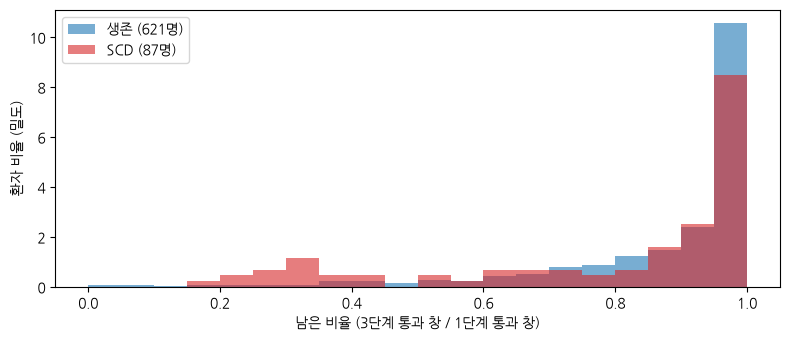

In [36]:
# 3-4 ③ 전체 결과 요약: 환자별로 얼마나 남았나 → SCD vs 생존 · 리듬별 · 많이 깎인 환자
SUMMARY_PATH = OUT / "sqi_full_summary.csv"
RHYTHM_NAME = {0: "동리듬", 1: "심방세동", 2: "심방조동", 3: "페이스메이커", 4: "기타"}
N_LOWEST = 10                     # 가장 많이 깎인 환자 몇 명을 보여줄지 (보기용, 판정 기준 아님)


# ① 환자별 결과 모으기
def patient_row(pid):
    """환자 한 명의 npz → 1단계 통과 창 수, 최종 쓸 수 있는 창 수, 남은 비율"""
    z = np.load(FULL_DIR / f"{pid}.npz")
    n_stage1, n_usable = int(z["stage1_clean"].sum()), int(z["usable"].sum())
    return {"pid": pid, "scd": pat.at[pid, "label_scd"],
            "rhythm": RHYTHM_NAME.get(pat.at[pid, "holter_rhythm"], "모름"), "leads": pat.at[pid, "leads"],
            "n_stage1": n_stage1, "n_usable": n_usable,
            "usable_hours": n_usable * WIN_SEC / 3600,
            "keep_rate": n_usable / n_stage1 if n_stage1 else np.nan}


summary = pd.DataFrame([patient_row(pid) for pid in pat.index])
summary.to_csv(SUMMARY_PATH, index=False, encoding="utf-8-sig")
print("저장:", SUMMARY_PATH, "/", len(summary), "명")


# ② 묶음별 비교: 남은 비율(3단계 통과 / 1단계 통과)과 쓸 수 있는 시간
def describe(group_col):
    """묶음마다 환자 수, 남은 비율 중앙값·평균·최저, 쓸 수 있는 시간 중앙값"""
    return summary.groupby(group_col).agg(
        환자=("pid", "size"),
        남은비율_중앙값=("keep_rate", "median"), 남은비율_평균=("keep_rate", "mean"), 남은비율_최저=("keep_rate", "min"),
        쓸수있는시간_중앙값=("usable_hours", "median")).round(3)


print("\n[전체]")
display(summary[["keep_rate", "usable_hours"]].describe().round(3))
print("\n[SCD(1) vs 생존(0)]")
display(describe("scd"))
print("\n[리듬별]")
display(describe("rhythm"))


# ③ 가장 많이 깎인 환자: 진짜 잡음인지 검출기 실패인지 나중에 그림으로 확인할 후보
print(f"\n[가장 많이 깎인 {N_LOWEST}명]")
display(summary.nsmallest(N_LOWEST, "keep_rate"))


# ④ 그림: 남은 비율 분포 (SCD vs 생존)
fig, ax = plt.subplots(figsize=(8, 3.5))
bins = np.linspace(0, 1, 21)
for label, name, color in [(0, "생존", "tab:blue"), (1, "SCD", "tab:red")]:
    ax.hist(summary.loc[summary["scd"] == label, "keep_rate"], bins=bins, alpha=0.6,
            density=True, color=color, label=f"{name} ({(summary['scd'] == label).sum()}명)")
ax.set_xlabel("남은 비율 (3단계 통과 창 / 1단계 통과 창)")
ax.set_ylabel("환자 비율 (밀도)")
ax.legend()
plt.tight_layout()
fig.savefig(OUT / "sqi_full_keep_rate.png", dpi=80)
plt.show()


In [37]:
# 팀 공유 ① 10초 창 파일 만들기: 1단계 통과 창 (덩어리 끝 창 제외, B 방식 DL 필터, float16) + 3단계 표시 (창 전체 · 유도별) + 분할
from joblib import Parallel, delayed
import hashlib

SHARE_DIR = Path("/mnt/c/data/music/SCD_Holter_DL_10s")   # 윈도우에서는 C:\data\music\SCD_Holter_DL_10s
SHARE_WIN_DIR = SHARE_DIR / "windows"                      # 환자별 파형 (npy)
SHARE_INDEX_DIR = SHARE_DIR / "index"                      # 창 목록 · 환자 목록 · 분할
BY_PATIENT_DIR = SHARE_INDEX_DIR / "by_patient"            # 환자별 창 목록 (중간 저장, 마지막에 하나로 합침)
LEAD_ORDER = ("X", "Y", "Z")      # 저장 순서 고정. 없는 유도는 0으로 채움
SPLIT_SEED = 42                   # 분할 순서를 고정하는 값 (누가 돌려도 같은 분할)
SPLIT_NAME = "split_team_v1"      # 분할 파일 이름 (분할 방식이 바뀌면 v2, v3 …로 새 파일)
N_JOBS = 6                        # 동시에 처리할 환자 수 (3-4 ②와 같음)
EDGE_SEC = 3.5                    # 덩어리 끝 사용 불가 (2단계 2-3). 10초 창보다 짧아 덩어리의 첫·마지막 창이 통째로 빠짐
for folder in (SHARE_WIN_DIR, BY_PATIENT_DIR):
    folder.mkdir(parents=True, exist_ok=True)


# ① 학습/검증/시험 분할: 960명 코호트에 80/20 → 80/20으로 매긴 뒤 708명에 그대로 이어 씀
def assign_splits(ids_by_target):
    """정답별로 sha256 순서로 정렬 → 80% 학습용 묶음 / 20% 시험 → 학습용 묶음을 다시 80% 학습 / 20% 검증"""
    assignments = {}
    for target, ids in ids_by_target.items():
        ids = sorted(ids, key=lambda p: (hashlib.sha256(f"{SPLIT_SEED}:{target}:{p}".encode()).hexdigest(), p))
        n_pool = len(ids) * 80 // 100           # 학습용 묶음 (학습 + 검증)
        n_train = n_pool * 80 // 100            # 그중 학습
        for i, p in enumerate(ids):
            assignments[p] = "train" if i < n_train else "validation" if i < n_pool else "test"
    return assignments


cohort = pd.read_csv(ROOT / "data" / "music" / "subject-info.csv", sep=";")
cohort.columns = cohort.columns.str.strip()
cohort = cohort[~cohort["Exit of the study"].isin([1, 2])]                 # 추적탈락 · 이식 제외
cohort = cohort[cohort["Age"].astype(str).str.strip() != ">89"]            # 나이 >89 제외
assert len(cohort) == 960
cohort_label = (cohort["Cause of death"] == 3).astype(int)
split = assign_splits({t: cohort.loc[cohort_label == t, "Patient ID"].tolist() for t in (0, 1)})


# ② 환자 한 명: 깨끗한 덩어리마다 DL 필터 (B 방식) → 덩어리 끝 창을 뺀 창만 잘라 저장 + 창 목록 저장
def clean_runs(clean):
    """깨끗한 창이 이어진 덩어리 → [(첫 창, 마지막 창 + 1), ...]"""
    edges = np.flatnonzero(np.diff(np.r_[0, clean.astype(int), 0]))
    return list(zip(edges[::2], edges[1::2]))


def run_edge(clean):
    """덩어리의 첫 창·마지막 창 → True (끝 EDGE_SEC초에 필터 출렁임이 남아 사용 불가)"""
    edge = np.zeros(len(clean), dtype=bool)
    for a, b in clean_runs(clean):
        edge[a] = edge[b - 1] = True
    return edge


def filter_by_run(x_mv, clean):
    """B 방식 (2단계 2-3): 버린 창에서 기록을 끊고, 깨끗한 덩어리마다 따로 DL 필터. 버린 창 자리는 0"""
    win = WIN_SEC * FS
    out = np.zeros(len(clean) * win)
    for a, b in clean_runs(clean):
        out[a * win:b * win] = dl_filter(x_mv[a * win:b * win], FS)
    return out


def window_waveforms(pid, z, keep):
    """남길 창들의 DL 필터 파형 → (창 수, 3, 2000) float16. 없는 유도는 0"""
    win = WIN_SEC * FS
    clean = z["stage1_clean"]
    n_win = len(clean)
    rec = wfdb.rdrecord(str(HOLTER / pid), physical=False, return_res=16)
    out = np.zeros((len(keep), len(LEAD_ORDER), win), dtype=np.float16)
    for i, lead in enumerate(LEAD_ORDER):
        if lead not in list(z["leads"]):
            continue
        j = rec.sig_name.index(lead)
        x_mv = rec.d_signal[:n_win * win, j] / rec.adc_gain[j]
        out[:, i, :] = filter_by_run(x_mv, clean).reshape(n_win, win)[keep]
    return out


def window_table(pid, z, keep):
    """창 한 줄씩: npy 안 순서, 원래 창 번호, 시각, 3단계 통과(창 전체 · 유도별 점수와 통과)"""
    table = pd.DataFrame({"pid": pid, "row": np.arange(len(keep)), "win_idx": keep,
                          "start_sec": keep * WIN_SEC, "hour": np.round(window_hour(pid, keep), 2),
                          "sqi_pass": z["usable"][keep].astype(int)})
    leads = list(z["leads"])
    for lead in LEAD_ORDER:
        if lead in leads:
            k = leads.index(lead)
            score, hr = z["bsqi"][k, keep], z["hr"][k, keep]
            table[f"sqi_{lead}"] = np.round(score, 3)
            table[f"pass_{lead}"] = ((score >= FINAL_BSQI) & (hr >= HR_LOW_BPM)).astype(int)
        else:
            table[f"sqi_{lead}"] = np.nan                  # 없는 유도
            table[f"pass_{lead}"] = -1                     # -1 = 유도 없음
    return table


def export_patient(pid):
    """환자 한 명 저장: windows/환자.npy + index/by_patient/환자.csv"""
    z = np.load(FULL_DIR / f"{pid}.npz")
    clean = z["stage1_clean"]
    keep = np.flatnonzero(clean & ~run_edge(clean))      # 1단계 통과 + 덩어리 끝 창 제외
    np.save(SHARE_WIN_DIR / f"{pid}.npy", window_waveforms(pid, z, keep))
    window_table(pid, z, keep).to_csv(BY_PATIENT_DIR / f"{pid}.csv", index=False)


# ③ 708명 처리: 이미 끝난 환자는 건너뜀 (중간에 멈춰도 다시 실행하면 이어서)
todo = [pid for pid in pat.index if not (BY_PATIENT_DIR / f"{pid}.csv").exists()]
print("할 환자:", len(todo), "/", len(pat))
t0 = time.time()
Parallel(n_jobs=N_JOBS, verbose=10)(delayed(export_patient)(pid) for pid in todo)
print(f"끝: {(time.time() - t0) / 3600:.1f}시간")


# ④ 창 목록 하나로 합치기 + 환자 목록 + 분할 (분할은 따로 저장: 바뀌면 이 파일만 새로 만들면 됨)
windows = pd.concat([pd.read_csv(BY_PATIENT_DIR / f"{pid}.csv") for pid in pat.index], ignore_index=True)
windows.to_csv(SHARE_INDEX_DIR / "windows.csv.gz", index=False)

patients = pd.DataFrame({
    "pid": pat.index,
    "label_scd": pat["label_scd"].values,
    "leads": pat["leads"].values,
    "n_windows": windows.groupby("pid").size().reindex(pat.index).values,
    "n_sqi_pass": windows.groupby("pid")["sqi_pass"].sum().reindex(pat.index).values,
})
patients.to_csv(SHARE_INDEX_DIR / "patients.csv", index=False, encoding="utf-8-sig")

split_table = pd.DataFrame({"pid": pat.index, "split": pat.index.map(split)})
split_table.to_csv(SHARE_INDEX_DIR / f"{SPLIT_NAME}.csv", index=False, encoding="utf-8-sig")


# ⑤ 확인: 분할별 인원, 전체 창 수, 폴더 용량
display(pd.crosstab(split_table["split"], patients["label_scd"], margins=True))
size_gb = sum(f.stat().st_size for f in SHARE_WIN_DIR.glob("*.npy")) / 1e9
print(f"창 {len(windows):,}개 (3단계 통과 {windows['sqi_pass'].sum():,}개) · 파형 파일 {size_gb:.1f} GB")


할 환자: 708 / 708


[Parallel(n_jobs=6)]: Using backend LokyBackend with 6 concurrent workers.
[Parallel(n_jobs=6)]: Done   1 tasks      | elapsed:    3.5s
[Parallel(n_jobs=6)]: Done   6 tasks      | elapsed:    3.9s
[Parallel(n_jobs=6)]: Done  13 tasks      | elapsed:    9.1s
[Parallel(n_jobs=6)]: Done  20 tasks      | elapsed:   12.1s
[Parallel(n_jobs=6)]: Done  29 tasks      | elapsed:   15.3s
[Parallel(n_jobs=6)]: Done  38 tasks      | elapsed:   20.5s
[Parallel(n_jobs=6)]: Done  49 tasks      | elapsed:   25.3s
[Parallel(n_jobs=6)]: Done  60 tasks      | elapsed:   29.3s
[Parallel(n_jobs=6)]: Done  73 tasks      | elapsed:   35.6s
[Parallel(n_jobs=6)]: Done  86 tasks      | elapsed:   43.6s
[Parallel(n_jobs=6)]: Done 101 tasks      | elapsed:   51.2s
[Parallel(n_jobs=6)]: Done 116 tasks      | elapsed:   59.4s
[Parallel(n_jobs=6)]: Done 133 tasks      | elapsed:  1.1min
[Parallel(n_jobs=6)]: Done 150 tasks      | elapsed:  1.3min
[Parallel(n_jobs=6)]: Done 169 tasks      | elapsed:  1.5min
[Parallel(

끝: 0.1시간


label_scd,0,1,All
split,,,
test,116,18,134
train,406,54,460
validation,99,15,114
All,621,87,708


창 5,868,655개 (3단계 통과 5,087,754개) · 파형 파일 70.4 GB
